# Projet Actuariat — Pricing Automobile
### Groupe G3 — Notebook complet (parties A à F)

Ce notebook enchaîne l'ensemble du travail, des fichiers bruts jusqu'à la comparaison des tarifs :

| Partie | Objet | Entrées | Sorties |
| --- | --- | --- | --- |
| **A** | Fiabilisation des données | `groupe3_base1_contrats.xlsx`, `groupe3_base2_sinistres.xlsx` | `contrats_propres.csv`, `sinistres_propres.csv`, `base_agregee.csv` |
| **B** | Séparation attritionnels / graves (méthode POT) | sorties de A | `sinistres_B.csv`, `base_B.csv` |
| **C** | Approche fréquence × coût | `base_B` | primes pures par segment |
| **D** | Modélisation GLM (fréquence Poisson, coût Gamma) | `base_B` | modèles ajustés |
| **E** | Comparaison de quatre approches de pricing | modèles de D | tableau comparatif |
| **F** | Séparation Train / Test et validation | `base_B` | écart observé / prédit |
| — | Synthèse | | points clés pour le rapport |

**Méthode suivie de bout en bout :** on regarde d'abord, on corrige ensuite ; chaque décision
est justifiée dans un tableau *Problème / Décision* ; chaque étape se termine par une
vérification qui rejoue tous les contrôles.

Le notebook s'exécute d'un bloc (*Run All*) depuis le dossier qui contient les deux fichiers Excel.

## 0. Environnement et paramètres communs

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
np.random.seed(42)

# Charte graphique : bleu = attritionnel, orange = grave, gris = repères
BLEU, ORANGE, GRIS, ENCRE, AQUA = '#2a78d6', '#eb6834', '#898781', '#52514e', '#1baf7a'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'axes.axisbelow': True, 'grid.linewidth': 0.6,
                     'axes.edgecolor': GRIS, 'axes.labelcolor': ENCRE, 'xtick.color': ENCRE,
                     'ytick.color': ENCRE, 'axes.titlesize': 11, 'axes.titleweight': 'bold'})

---
# Partie A — Fiabilisation des données

1. Chargement des données
2. Étude de la base **Contrats**, variable par variable
3. Problèmes identifiés — Contrats
4. Corrections — Contrats
5. Vérification et export de la base Contrats
6. Étude de la base **Sinistres**, variable par variable
7. Problèmes identifiés — Sinistres
8. Corrections — Sinistres
9. Jointure Contrats × Sinistres et base agrégée

**Principe :** une ligne n'est supprimée que si elle est inutilisable ; sinon elle est corrigée
ou conservée telle quelle avec une justification.

## A.1 Chargement des données

In [2]:
def lit_dates(d):
    """Convertit une colonne de dates stockées sous plusieurs formats, en les essayant un par un.
    Pas de dayfirst=True : il inverserait jour et mois sur les dates au format aaaa-mm-jj."""
    serie_excel = pd.to_numeric(d.map(lambda v: v if isinstance(v, (int, float)) else None),
                                errors='coerce')                  # numéro de série Excel (jours)
    return (pd.to_datetime(d, format='%Y-%m-%d', errors='coerce')
              .fillna(pd.to_datetime(d, format='%Y-%m-%d %H:%M:%S', errors='coerce'))
              .fillna(pd.to_datetime(d, format='%d/%m/%Y', errors='coerce'))
              .fillna(pd.to_datetime(d, format='%Y/%m/%d', errors='coerce'))
              .fillna(pd.to_datetime(serie_excel, unit='D', origin='1899-12-30')))

contrats  = pd.read_excel('groupe3_base1_contrats.xlsx')
sinistres = pd.read_excel('groupe3_base2_sinistres.xlsx', dtype={'montant_sinistre': str})

# On garde une copie des identifiants d'origine (utile à la jointure, section 9)
ids_contrats_origine = set(contrats['id_police'].astype(str).str.strip())
n_contrats_depart, n_sinistres_depart = len(contrats), len(sinistres)

print('Contrats  :', contrats.shape)
print('Sinistres :', sinistres.shape)
contrats.head()

Contrats  : (21603, 14)
Sinistres : (1320, 7)


,id_police,date_effet_contrat,duree_exposition,age_conducteur,sexe,anciennete_permis,bonus_malus,zone_geo,usage_vehicule,puissance_fiscale,classe_vehicule,age_vehicule,carburant,type_couverture
0,POL115969,2023-10-04 00:00:00,0.920,53.0,F,32.0,0.94,D,Mixte,7,SUV,1,Essence,Tous risques
1,POL114700,2023-02-18 00:00:00,0.189,23.0,F,0.0,0.92,B,Professionnel,5,Citadine,22,Diesel,Tiers étendu
2,POL120388,2023-10-06 00:00:00,0.912,36.0,F,17.0,0.55,C,Mixte,7,Citadine,13,Essence,Tiers
3,POL100656,2023-05-14 00:00:00,0.232,71.0,F,53.0,0.71,E,Mixte,6,Citadine,16,Essence,Tiers étendu
4,POL121129,2023-04-29 00:00:00,0.786,61.0,M,41.0,0.69,D,Mixte,9,Sportive,1,Hybride,Tiers


## A.2 Étude de la base Contrats

### A.2.1 Vue d'ensemble : type et valeurs manquantes

In [3]:
apercu = pd.DataFrame({
    'type'       : contrats.dtypes.astype(str),
    'n_manquants': contrats.isna().sum(),
    'pct'        : (contrats.isna().mean() * 100).round(2),
    'n_valeurs'  : contrats.nunique()
})
print('Lignes :', len(contrats), ' | lignes entièrement dupliquées :', contrats.duplicated().sum())
print('id_police dupliqués :', contrats['id_police'].duplicated().sum())
apercu

Lignes : 21603  | lignes entièrement dupliquées : 103
id_police dupliqués : 103


,type,n_manquants,pct,n_valeurs
id_police,str,0,0.00,21500
date_effet_contrat,object,0,0.00,587
duree_exposition,float64,0,0.00,854
age_conducteur,float64,340,1.57,76
sexe,str,0,0.00,8
anciennete_permis,float64,258,1.19,87
bonus_malus,float64,258,1.19,129
zone_geo,str,174,0.81,5
usage_vehicule,str,0,0.00,6
puissance_fiscale,int64,0,0.00,16


### A.2.2 `date_effet_contrat` — date de prise d'effet du contrat

Jour où la garantie commence à courir. Sert à délimiter la période de couverture (contrôle de
la section 9) et à répartir l'exposition entre 2023 et 2024.

**Attendu :** une date comprise dans la période d'étude.
**À vérifier :** le format de stockage et la présence de valeurs manquantes.

In [4]:
print('Types de valeurs rencontrés :')
print(contrats['date_effet_contrat'].map(lambda v: type(v).__name__).value_counts().to_string())
print('\nExemples :', contrats['date_effet_contrat'].head(3).tolist())

# Conversion format par format (fonction lit_dates, section A.1)
dates = lit_dates(contrats['date_effet_contrat'])

print('\nDates non lisibles :', dates.isna().sum())
print('Plage :', dates.min(), '→', dates.max())
print('\nRépartition par année :')
print(dates.dt.year.value_counts().sort_index().to_string())

Types de valeurs rencontrés :
date_effet_contrat
datetime    21257
str           344
int             2

Exemples : [datetime.datetime(2023, 10, 4, 0, 0), datetime.datetime(2023, 2, 18, 0, 0), datetime.datetime(2023, 10, 6, 0, 0)]

Dates non lisibles : 0
Plage : 2023-01-01 00:00:00 → 2023-12-31 00:00:00

Répartition par année :
date_effet_contrat
2023    21603


### A.2.3 `duree_exposition` — durée d'exposition au risque

Temps pendant lequel l'assureur a effectivement porté le risque, exprimé en **années-police**
(0,5 = six mois). C'est l'unité de compte de la tarification : elle servira d'offset
`log(exposition)` au GLM fréquence.

**Attendu :** une valeur dans ]0 ; 1].
**Problème si :** valeur manquante, nulle ou négative (le logarithme n'existe pas), ou
supérieure à 1 an.

In [5]:
expo = pd.to_numeric(contrats['duree_exposition'], errors='coerce')
print(expo.describe(percentiles=[.05, .25, .5, .75, .95]).round(3).to_string())
print('\nManquantes        :', expo.isna().sum())
print('Nulles ou < 0     :', (expo <= 0).sum())
print('Supérieures à 1   :', (expo > 1).sum())
print('\nValeurs hors ]0 ; 1] :', expo[(expo <= 0) | (expo > 1)].value_counts().sort_index().to_dict())
mois = pd.to_datetime(contrats['date_effet_contrat'], format='mixed', errors='coerce').dt.month
print('Exposition médiane par mois de souscription (valeurs valides) :',
      expo[(expo > 0) & (expo <= 1)].groupby(mois).median().round(2).to_dict())

count    21603.000
mean         0.576
std          0.251
min          0.000
5%           0.192
25%          0.363
50%          0.570
75%          0.788
95%          0.960
max          2.000

Manquantes        : 0
Nulles ou < 0     : 15
Supérieures à 1   : 38

Valeurs hors ]0 ; 1] : {0.0: 15, 1.35: 16, 2.0: 22}
Exposition médiane par mois de souscription (valeurs valides) : {1: 0.58, 2: 0.58, 3: 0.59, 4: 0.56, 5: 0.56, 6: 0.58, 7: 0.58, 8: 0.56, 9: 0.56, 10: 0.58, 11: 0.57, 12: 0.55}


### A.2.4 `age_conducteur` et `anciennete_permis`

L'âge est un facteur de fréquence majeur, avec une relation en U : les jeunes conducteurs et
les conducteurs très âgés sont plus sinistrés. Il sera donc découpé en classes, jamais utilisé
en continu dans un GLM.

L'ancienneté mesure l'expérience de conduite. Elle est très corrélée à l'âge : une seule des
deux devra figurer dans un même modèle.

**Attendu :** âge entre 18 et 99 ans, ancienneté positive, et `âge − ancienneté ≥ 18`
puisqu'on ne passe pas le permis avant 18 ans.

In [6]:
age = pd.to_numeric(contrats['age_conducteur'], errors='coerce')
anc = pd.to_numeric(contrats['anciennete_permis'], errors='coerce')

print(pd.DataFrame({'age': age, 'anciennete': anc}).describe(percentiles=[.01, .5, .99]).round(1).to_string())
print('\nage manquant             :', age.isna().sum())
print('age < 18                 :', (age < 18).sum())
print('age > 99                 :', (age > 99).sum())
print('ancienneté manquante     :', anc.isna().sum())
print('ancienneté > âge         :', (anc > age).sum())
print('âge - ancienneté < 18    :', ((age - anc) < 18).sum())
print('les deux manquants       :', (age.isna() & anc.isna()).sum())
print('\nÂges hors [18 ; 99] :', age[(age < 18) | (age > 99)].value_counts().sort_index().to_dict())
ok_ = age.between(18, 99) & anc.notna() & (age - anc >= 18)
print(f'Sur les {ok_.sum()} contrats cohérents : âge − ancienneté entre {(age - anc)[ok_].min():.0f} et '
      f'{(age - anc)[ok_].max():.0f} ans, corrélation âge / ancienneté = {np.corrcoef(age[ok_], anc[ok_])[0, 1]:.3f}')
print('\nExemples d\'anciennetés supérieures à l\'âge :')
print(contrats.loc[anc > age, ['id_police', 'age_conducteur', 'anciennete_permis']].head().to_string(index=False))

           age  anciennete
count  21263.0     21345.0
mean      42.5        22.1
std       13.9        12.8
min        3.0         0.0
1%        18.0         0.0
50%       42.0        22.0
99%       73.0        54.0
max      210.0        89.0

age manquant             : 340
age < 18                 : 33
age > 99                 : 35
ancienneté manquante     : 258
ancienneté > âge         : 83
âge - ancienneté < 18    : 85
les deux manquants       : 4

Âges hors [18 ; 99] : {3.0: 17, 5.0: 16, 150.0: 21, 210.0: 14}
Sur les 20889 contrats cohérents : âge − ancienneté entre 18 et 23 ans, corrélation âge / ancienneté = 0.991

Exemples d'anciennetés supérieures à l'âge :
id_police  age_conducteur  anciennete_permis
POL116046             5.0               29.0
POL119031            50.0               79.0
POL116975            54.0               75.0
POL112529            47.0               89.0
POL107199            33.0               70.0


### A.2.5 `bonus_malus` — coefficient de réduction-majoration

Multiplicateur appliqué à la prime : 0,80 signifie que l'assuré paie 80 % du tarif de base.
Tout conducteur démarre à 1,00 ; chaque année sans sinistre responsable applique −5 %, chaque
sinistre responsable +25 %.

**Attendu :** une valeur entre 0,50 (plancher réglementaire) et 3,50 (plafond).

**Contrôle de cohérence.** Le coefficient ne pouvant baisser que de 5 % par an, il ne peut pas
descendre en dessous de `max(0,50 ; 0,95^ancienneté)`. Atteindre 0,50 demande ainsi 13 années
de conduite sans sinistre. C'est une **borne inférieure**, pas une valeur attendue : la base ne
contient pas l'ancienneté d'assurance, qui gouverne réellement le coefficient et qui est
inférieure ou égale à l'ancienneté de permis.

In [7]:
bm = pd.to_numeric(contrats['bonus_malus'], errors='coerce')
print(bm.describe(percentiles=[.05, .5, .95]).round(3).to_string())
print('\nManquant                            :', bm.isna().sum())
print('Hors [0,50 ; 3,50]                  :', ((bm < 0.50) | (bm > 3.50)).sum())
print('0,50 avec moins de 13 ans de permis :', ((bm <= 0.50) & (anc < 13)).sum())
print('Sous la borne 0,95^ancienneté       :', (bm < np.maximum(0.50, 0.95 ** anc) - 1e-6).sum())
print('\nValeurs hors bornes :', bm[(bm < 0.50) | (bm > 3.50)].value_counts().sort_index().to_dict())
print(f'Corrélation bonus-malus / ancienneté (valeurs valides) : '
      f'{bm[bm.between(0.5, 3.5)].corr(anc):.3f}')

count    21345.000
mean         0.870
std          0.436
min         -0.500
5%           0.500
50%          0.850
95%          1.260
max         12.000

Manquant                            : 258
Hors [0,50 ; 3,50]                  : 68
0,50 avec moins de 13 ans de permis : 434
Sous la borne 0,95^ancienneté       : 2030

Valeurs hors bornes : {-0.5: 24, 0.0: 21, 12.0: 23}
Corrélation bonus-malus / ancienneté (valeurs valides) : 0.006


### A.2.6 `puissance_fiscale` et `age_vehicule`

La puissance fiscale (en CV) figure sur la carte grise : donnée objective, liée à la gravité
des chocs et au coût de réparation. L'âge du véhicule joue en sens inverse sur le coût : un
véhicule ancien a une valeur vénale faible, donc une indemnisation plus basse.

**Attendu :** puissance entre 2 et 20 CV, âge du véhicule entre 0 et 35 ans.

In [8]:
pf = pd.to_numeric(contrats['puissance_fiscale'], errors='coerce')
av = pd.to_numeric(contrats['age_vehicule'], errors='coerce')
print(pd.DataFrame({'puissance': pf, 'age_vehicule': av}).describe(percentiles=[.01, .5, .99]).round(1).to_string())
print('\npuissance manquante ou hors [2 ; 20] :', (pf.isna() | (pf < 2) | (pf > 20)).sum())
print('age_vehicule manquant ou hors [0 ; 35]:', (av.isna() | (av < 0) | (av > 35)).sum())

       puissance  age_vehicule
count    21603.0       21603.0
mean         7.7           5.9
std          3.4           5.6
min          0.0           0.0
1%           3.0           0.0
50%          7.0           4.0
99%         14.0          25.0
max         99.0          25.0

puissance manquante ou hors [2 ; 20] : 51
age_vehicule manquant ou hors [0 ; 35]: 0


### A.2.7 Variables catégorielles

- **`sexe`** — effet faible sur la fréquence (interdit comme critère tarifaire dans l'Union
  européenne depuis 2012, conservé ici pour l'analyse).
- **`zone_geo`** — zonier A à E : densité de circulation, taux de vol, coût de la main-d'œuvre.
- **`usage_vehicule`** — un usage professionnel implique plus de kilomètres, donc plus de risque.
- **`classe_vehicule`** — agit surtout sur le coût de réparation.
- **`carburant`** — les motorisations électriques et hybrides coûtent plus cher à réparer.
- **`type_couverture`** — périmètre des garanties : Tiers (responsabilité civile seule), Tiers
  étendu (+ vol, incendie, bris de glace, catastrophes naturelles), Tous risques. C'est la base
  du contrôle de cohérence avec les sinistres, en section 9.

**Attendu :** uniquement les modalités officielles, sans variante d'écriture ni valeur manquante.

In [9]:
var_cat = ['sexe', 'zone_geo', 'usage_vehicule', 'classe_vehicule', 'carburant', 'type_couverture']
for col in var_cat:
    print(f'--- {col} ---')
    print(contrats[col].value_counts(dropna=False).to_string())
    print()

--- sexe ---
sexe
M        11801
F         9290
Homme      183
Femme      157
m           92
f           74
femme        5
homme        1

--- zone_geo ---
zone_geo
C      6506
D      4360
B      4197
A      3230
E      3136
NaN     174

--- usage_vehicule ---
usage_vehicule
Privé            13726
Mixte             4354
Professionnel     3265
PRIVÉ              171
PROFESSIONNEL       45
MIXTE               42

--- classe_vehicule ---
classe_vehicule
Citadine          7471
Berline           5278
SUV               4718
Utilitaire        2822
Sportive          1055
  Citadine          96
  Berline           59
  SUV               51
  Utilitaire        43
  Sportive          10

--- carburant ---
carburant
Essence       9622
Diesel        7392
Hybride       2668
Électrique    1565
NaN            344
Electrique      12

--- type_couverture ---
type_couverture
Tous risques    9655
Tiers étendu    6604
Tiers           5344



---
## A.3 Problèmes identifiés — Base Contrats

| Variable | Problème constaté | Décision |
| --- | --- | --- |
| `id_police` | 103 identifiants présents deux fois | **vérifié (A.4.1) : les deux occurrences sont identiques sur les 14 colonnes**, aucun identifiant n'est partagé par deux contrats différents. Une occurrence est supprimée : un doublon compterait deux fois l'exposition |
| `date_effet_contrat` | trois formats coexistent : dates Excel, texte `jj/mm/aaaa` et 2 numéros de série Excel stockés en entier | conversion format par format (`lit_dates`), sans `dayfirst` |
| `duree_exposition` | trois valeurs codées : 0 (15 contrats), 1,35 (15) et 2,00 (21) | **correction, sans suppression.** Au-delà de 1 an, l'exposition est plafonnée à 1 : un contrat annuel ne peut pas exposer plus d'un an. Une exposition nulle est impossible pour un contrat émis ; elle reçoit l'exposition médiane du portefeuille, seule estimation disponible (l'exposition ne dépend ni du mois de souscription ni d'aucune autre variable). Indicateur `expo_corrigee` |
| `age_conducteur` | valeurs codées 3, 5, 150 et 210 (68 contrats) et 340 valeurs manquantes | **reconstruction à partir de l'ancienneté de permis**, et non par une médiane : sur les contrats cohérents, âge − ancienneté est toujours compris entre 18 et 23 ans (corrélation 0,99). La précision est mesurée en A.4.3 sur des âges connus masqués. Si l'ancienneté manque aussi, l'âge reste **inconnu** : le contrat est conservé et reçoit la classe d'âge `Inconnu` |
| `anciennete_permis` | manquante, ou supérieure à un âge valide | même relation, utilisée dans l'autre sens. L'ancienneté n'est jugée aberrante que par rapport à un âge **valide** : un âge codé (3 ans) ne doit pas faire rejeter une ancienneté correcte |
| `bonus_malus` | trois valeurs codées : −0,5 (24), 0 (21) et 12 (23) | **conversion, pas de remplacement.** −0,5 est un taux de réduction de 50 %, soit un coefficient 0,50 ; 0 est un taux nul, soit un coefficient 1,00 ; 12 est le coefficient 1,2 dont la virgule a été perdue. Indicateur `bm_corrige` |
| `bonus_malus` | 258 valeurs manquantes | **non imputées** : aucune variable ne permet de les reconstruire (corrélation avec l'ancienneté ≈ 0). Classe de bonus-malus `Inconnu` |
| `bonus_malus` | coefficient sous la borne `0,95^ancienneté` (part importante du portefeuille) | **conservé sans correction** : on ignore laquelle des deux variables est fausse. Anomalie documentée |
| `puissance_fiscale`, `age_vehicule` | valeurs hors bornes | médiane de la classe de véhicule |
| variables catégorielles | variantes d'écriture et valeurs manquantes | recodage des variantes ; manquants remplacés par la modalité la plus fréquente |

**Règle générale :** aucun contrat n'est supprimé pour une valeur corrigible. On corrige ce qui peut
l'être, et on déclare `Inconnu` ce qui ne peut pas être reconstruit plutôt que d'inventer une valeur.

---
## A.4 Corrections — Base Contrats

### A.4.1 Doublons (vérifiés) et date d'effet

In [10]:
# Vérification : un même id_police porte-t-il des informations différentes ?
dup = contrats[contrats['id_police'].duplicated(keep=False)]
n_diff = int((dup.astype(str).groupby('id_police').nunique().max(axis=1) > 1).sum())
print('Identifiants en double :', dup['id_police'].nunique(), '| dont avec des informations différentes :', n_diff)

n = len(contrats)
contrats = contrats.drop_duplicates().copy()
print('Doublons supprimés :', n - len(contrats), '| reste', len(contrats))

contrats['date_effet_contrat'] = lit_dates(contrats['date_effet_contrat'])
print('Dates non lisibles restantes :', contrats['date_effet_contrat'].isna().sum())

# Même identifiant, contenu différent : on garde la ligne la plus récente
if contrats['id_police'].duplicated().any():
    n = len(contrats)
    contrats = (contrats.sort_values(['id_police', 'date_effet_contrat'])
                        .drop_duplicates('id_police', keep='last')
                        .sort_index().copy())
    print('Identifiants dupliqués supprimés :', n - len(contrats), '| reste', len(contrats))
else:
    print('id_police est bien unique')

Identifiants en double : 103 | dont avec des informations différentes : 0
Doublons supprimés : 103 | reste 21500
Dates non lisibles restantes : 0
id_police est bien unique


### A.4.2 Exposition — correction des valeurs codées

In [11]:
contrats['duree_exposition'] = pd.to_numeric(contrats['duree_exposition'], errors='coerce')
e = contrats['duree_exposition']
trop_longue = e > 1
nulle = e.isna() | (e <= 0)
expo_mediane = e[(e > 0) & (e <= 1)].median()

contrats['expo_corrigee'] = (trop_longue | nulle).astype(int)
contrats.loc[trop_longue, 'duree_exposition'] = 1.0
contrats.loc[nulle, 'duree_exposition'] = expo_mediane
print(f'Expositions > 1 an plafonnées à 1 an        : {int(trop_longue.sum())}  (valeurs {sorted(e[trop_longue].unique())})')
print(f'Expositions nulles → médiane ({expo_mediane:.3f} an) : {int(nulle.sum())}')
print('Contrats supprimés : 0 | reste', len(contrats))
print('Exposition totale  :', round(contrats['duree_exposition'].sum(), 1), 'années-police')

Expositions > 1 an plafonnées à 1 an        : 36  (valeurs [np.float64(1.35), np.float64(2.0)])
Expositions nulles → médiane (0.570 an) : 15
Contrats supprimés : 0 | reste 21500
Exposition totale  : 12359.2 années-police


### A.4.3 Âge et ancienneté

Les âges aberrants sont des **codes** (3, 5, 150, 210), pas des fautes de frappe : on ne peut pas les
« corriger » chiffre par chiffre. En revanche, l'âge et l'ancienneté de permis sont liés presque
exactement (on obtient son permis entre 18 et 23 ans) : on **reconstruit** l'information manquante par
la droite âge = a + b × ancienneté ajustée sur les contrats cohérents.

Avant de l'appliquer, on mesure sa précision : on masque 2 000 âges connus, on les reconstruit, et on
compare avec un remplacement par l'âge médian.

In [12]:
contrats['age_conducteur']    = pd.to_numeric(contrats['age_conducteur'], errors='coerce')
contrats['anciennete_permis'] = pd.to_numeric(contrats['anciennete_permis'], errors='coerce')
a, p = contrats['age_conducteur'], contrats['anciennete_permis']

# 1. Codes et valeurs impossibles mis à NaN ; l'ancienneté n'est comparée qu'à un âge VALIDE
age_aberrant = (a < 18) | (a > 99)
a_valide = a.where(~age_aberrant)
anc_aberrante = (p < 0) | (p > a_valide) | ((a_valide - p) < 18)
print('Âges codés mis à NaN          :', int(age_aberrant.sum()), sorted(a[age_aberrant].unique()))
print('Anciennetés aberrantes à NaN  :', int(anc_aberrante.sum()))
contrats.loc[age_aberrant, 'age_conducteur'] = np.nan
contrats.loc[anc_aberrante, 'anciennete_permis'] = np.nan
a, p = contrats['age_conducteur'], contrats['anciennete_permis']

# 2. Relation âge / ancienneté sur les contrats complets
ok = a.notna() & p.notna()
print(f'\nContrats complets : {int(ok.sum())} | âge − ancienneté entre {(a - p)[ok].min():.0f} et '
      f'{(a - p)[ok].max():.0f} ans | corrélation {np.corrcoef(a[ok], p[ok])[0, 1]:.3f}')

# 3. Validation : 2 000 âges connus masqués puis reconstruits
rng = np.random.default_rng(42)
i_ok = np.flatnonzero(ok.values)
i_test = rng.choice(i_ok, size=2000, replace=False)
i_appr = np.setdiff1d(i_ok, i_test)
pente_v, const_v = np.polyfit(p.values[i_appr], a.values[i_appr], 1)
vrai = a.values[i_test]
candidats_age = {'âge médian du portefeuille'     : np.full(len(vrai), np.median(a.values[i_appr])),
                 "reconstruction par l'ancienneté": np.round(const_v + pente_v * p.values[i_test])}
bornes_age = [17, 25, 35, 50, 65, 200]
classe = lambda v: pd.cut(pd.Series(v), bornes_age).astype(str).values
print('\nValidation sur 2 000 âges connus masqués :')
for nom, pred in candidats_age.items():
    print(f'  {nom:<32}: erreur absolue moyenne {np.abs(vrai - pred).mean():4.1f} ans | '
          f"classe d'âge correcte {np.mean(classe(vrai) == classe(pred)) * 100:5.1f} %")

# 4. Reconstruction sur tout le portefeuille
pente, const = np.polyfit(p[ok], a[ok], 1)
print(f'\nDroite retenue : âge = {const:.2f} + {pente:.3f} × ancienneté')
age_manq, anc_manq = a.isna() & p.notna(), p.isna() & a.notna()
contrats.loc[age_manq, 'age_conducteur'] = np.maximum(np.round(const + pente * p[age_manq]), p[age_manq] + 18).clip(18, 99)
contrats.loc[anc_manq, 'anciennete_permis'] = np.minimum(np.round((a[anc_manq] - const) / pente), a[anc_manq] - 18).clip(lower=0)
contrats['age_inconnu'] = contrats['age_conducteur'].isna().astype(int)
print('Âges reconstruits        :', int(age_manq.sum()))
print('Anciennetés reconstruites:', int(anc_manq.sum()))
print('Âge et ancienneté tous deux inconnus (contrats conservés, classe « Inconnu ») :', int(contrats['age_inconnu'].sum()))

a, p = contrats['age_conducteur'], contrats['anciennete_permis']
print('Incohérences restantes (âge - ancienneté < 18) :', int(((a - p) < 18).sum()))

Âges codés mis à NaN          : 68 [np.float64(3.0), np.float64(5.0), np.float64(150.0), np.float64(210.0)]
Anciennetés aberrantes à NaN  : 51

Contrats complets : 20789 | âge − ancienneté entre 18 et 23 ans | corrélation 0.991

Validation sur 2 000 âges connus masqués :
  âge médian du portefeuille      : erreur absolue moyenne 10.4 ans | classe d'âge correcte  42.6 %
  reconstruction par l'ancienneté : erreur absolue moyenne  1.5 ans | classe d'âge correcte  89.3 %

Droite retenue : âge = 20.42 + 0.998 × ancienneté
Âges reconstruits        : 404
Anciennetés reconstruites: 303
Âge et ancienneté tous deux inconnus (contrats conservés, classe « Inconnu ») : 4
Incohérences restantes (âge - ancienneté < 18) : 0


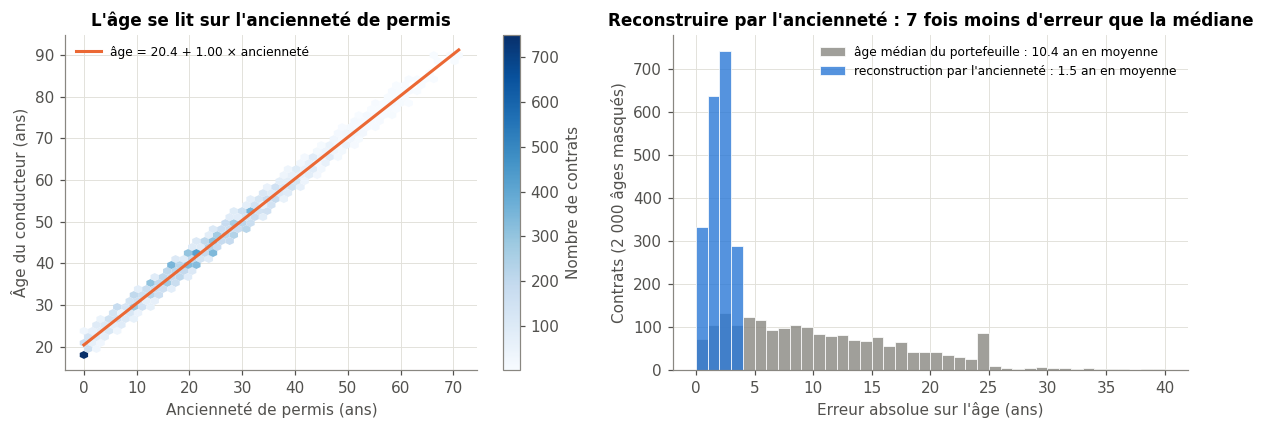

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
x_, y_ = contrats.loc[ok, 'anciennete_permis'], contrats.loc[ok, 'age_conducteur']
hb = ax.hexbin(x_, y_, gridsize=45, cmap='Blues', mincnt=1, linewidths=0)
xx = np.linspace(0, x_.max(), 50)
ax.plot(xx, const + pente * xx, color=ORANGE, lw=2, label=f'âge = {const:.1f} + {pente:.2f} × ancienneté')
ax.set_xlabel('Ancienneté de permis (ans)'); ax.set_ylabel('Âge du conducteur (ans)')
ax.set_title("L'âge se lit sur l'ancienneté de permis")
ax.legend(frameon=False, loc='upper left', fontsize=8)
fig.colorbar(hb, ax=ax, label='Nombre de contrats')

ax = axes[1]
for (nom, pred), col in zip(candidats_age.items(), [GRIS, BLEU]):
    err = np.abs(vrai - pred)
    ax.hist(err, bins=np.arange(0, 41, 1), color=col, alpha=0.8, edgecolor='white', linewidth=0.6,
            label=f'{nom} : {err.mean():.1f} an en moyenne')
ax.set_xlabel("Erreur absolue sur l'âge (ans)"); ax.set_ylabel('Contrats (2 000 âges masqués)')
ax.set_title("Reconstruire par l'ancienneté : 7 fois moins d'erreur que la médiane")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### A.4.4 Bonus-malus (conversion des codes), puissance et âge du véhicule

In [14]:
contrats['bonus_malus'] = pd.to_numeric(contrats['bonus_malus'], errors='coerce')
b = contrats['bonus_malus']

# Codes : -0,5 = taux de réduction de 50 % ; 0 = taux nul ; 12 = 1,2 sans sa virgule
conversion = {-0.5: 0.50, 0.0: 1.00, 12.0: 1.20}
code_bm = b.isin(list(conversion))
contrats['bm_corrige'] = code_bm.astype(int)
contrats.loc[code_bm, 'bonus_malus'] = b[code_bm].map(conversion)
print('Valeurs codées converties :', b[code_bm].value_counts().sort_index().to_dict(), '→', conversion)

autre = contrats['bonus_malus'].notna() & ~contrats['bonus_malus'].between(0.50, 3.50)
contrats.loc[autre, 'bonus_malus'] = np.nan
print('Autres valeurs hors [0,50 ; 3,50] mises à NaN :', int(autre.sum()))
print('Bonus-malus inconnus (non imputés, classe « Inconnu ») :', int(contrats['bonus_malus'].isna().sum()))

imputes_vehicule = {}
for col, mini, maxi in [('puissance_fiscale', 2, 20), ('age_vehicule', 0, 35)]:
    contrats[col] = pd.to_numeric(contrats[col], errors='coerce')
    x = contrats[col]
    mauvais = x.isna() | (x < mini) | (x > maxi)
    med = contrats.loc[~mauvais].groupby('classe_vehicule')[col].median()
    contrats.loc[mauvais, col] = contrats.loc[mauvais, 'classe_vehicule'].map(med).astype(float)
    contrats[col] = contrats[col].fillna(x[~mauvais].median()).round()
    imputes_vehicule[col] = int(mauvais.sum())
    print(f'{col} imputés : {mauvais.sum()}  (valeurs {sorted(x[mauvais].dropna().unique())})')

Valeurs codées converties : {-0.5: 24, 0.0: 21, 12.0: 23} → {-0.5: 0.5, 0.0: 1.0, 12.0: 1.2}
Autres valeurs hors [0,50 ; 3,50] mises à NaN : 0
Bonus-malus inconnus (non imputés, classe « Inconnu ») : 258
puissance_fiscale imputés : 51  (valeurs [np.int64(0), np.int64(45), np.int64(99)])
age_vehicule imputés : 0  (valeurs [])


### A.4.5 Variables catégorielles

Les variantes d'écriture sont recodées, puis les valeurs manquantes reçoivent la modalité la
plus fréquente. Aucune ligne n'est supprimée.

In [15]:
remplacements = {
    'sexe'           : {'Homme': 'M', 'Masculin': 'M', 'H': 'M',
                        'Femme': 'F', 'Féminin': 'F', 'Feminin': 'F','f':'F','h':'M','m':'M','femme':'F','homme':'M'},
    'usage_vehicule' : {'Prive': 'Privé','PRIVÉ':'Privé','PROFESSIONNEL': 'Professionnel','MIXTE': 'Mixte','Pro': 'Professionnel'},
    'classe_vehicule': {'Suv': 'SUV', 'suv': 'SUV'},
    'carburant'      : {'Electrique': 'Électrique', 'Gazole': 'Diesel'},
    'type_couverture': {'Tiers Etendu': 'Tiers étendu', 'Tiers etendu': 'Tiers étendu',
                        'Tous Risques': 'Tous risques'},
}

manquants_cat = {}
for col in var_cat:
    contrats[col] = contrats[col].astype('string').str.strip()
    if col in remplacements:
        contrats[col] = contrats[col].replace(remplacements[col])
    n_nan = contrats[col].isna().sum()
    manquants_cat[col] = int(n_nan)
    if n_nan:
        mode = contrats[col].mode()[0]
        contrats[col] = contrats[col].fillna(mode)
        print(f'{col:<17}: {n_nan} manquants remplacés par «{mode}»')
    else:
        print(f'{col:<17}: aucun manquant')

print('\nModalités après correction :')
for col in var_cat:
    print(f'  {col:<17}: {dict(contrats[col].value_counts())}')

sexe             : aucun manquant
zone_geo         : 172 manquants remplacés par «C»
usage_vehicule   : aucun manquant
classe_vehicule  : aucun manquant
carburant        : 344 manquants remplacés par «Essence»
type_couverture  : aucun manquant

Modalités après correction :
  sexe             : {'M': 12024, 'F': 9476}
  zone_geo         : {'C': 6652, 'D': 4337, 'B': 4177, 'A': 3215, 'E': 3119}
  usage_vehicule   : {'Privé': 13830, 'Mixte': 4378, 'Professionnel': 3292}
  classe_vehicule  : {'Citadine': 7536, 'Berline': 5309, 'SUV': 4745, 'Utilitaire': 2853, 'Sportive': 1057}
  carburant        : {'Essence': 9924, 'Diesel': 7348, 'Hybride': 2658, 'Électrique': 1570}
  type_couverture  : {'Tous risques': 9619, 'Tiers étendu': 6568, 'Tiers': 5313}


---
## A.5 Vérification et export — Base Contrats

Toutes les règles de la section 2 sont rejouées. Aucun contrôle ne doit rester à un chiffre
différent de zéro.

In [16]:
a, p, bmv = contrats['age_conducteur'], contrats['anciennete_permis'], contrats['bonus_malus']
e = contrats['duree_exposition']
controles = {
    'id_police dupliqué'                            : contrats['id_police'].duplicated().sum(),
    "date d'effet manquante"                        : contrats['date_effet_contrat'].isna().sum(),
    'exposition hors ]0 ; 1]'                       : (e.isna() | (e <= 0) | (e > 1)).sum(),
    'âge renseigné hors [18 ; 99]'                  : (a.notna() & ~a.between(18, 99)).sum(),
    "âge manquant, ancienneté connue"               : (a.isna() & p.notna()).sum(),
    "ancienneté manquante, âge connu"               : (p.isna() & a.notna()).sum(),
    'ancienneté négative'                           : (p < 0).sum(),
    'permis obtenu avant 18 ans'                    : ((a - p) < 18).sum(),
    'bonus-malus renseigné hors [0,50 ; 3,50]'      : (bmv.notna() & ~bmv.between(0.50, 3.50)).sum(),
    'puissance hors [2 ; 20]'                       : (~contrats['puissance_fiscale'].between(2, 20)).sum(),
    'âge véhicule hors [0 ; 35]'                    : (~contrats['age_vehicule'].between(0, 35)).sum(),
    'catégorielle manquante'                        : contrats[var_cat].isna().sum().sum(),
}
for nom, n in controles.items():
    print(f'  {"OK   " if n == 0 else "RESTE"}  {nom:<42} {int(n):>5}')

print(f"\nCorrigés  : exposition {int(contrats['expo_corrigee'].sum())} | bonus-malus {int(contrats['bm_corrige'].sum())}")
print(f"Inconnus conservés (classe « Inconnu ») : âge {int(a.isna().sum())} | bonus-malus {int(bmv.isna().sum())}")
print(f'Base contrats : {n_contrats_depart:,} → {len(contrats):,} lignes '
      f'({len(contrats) / n_contrats_depart * 100:.1f} % conservées ; seuls les doublons exacts sont retirés)')
contrats.to_csv('contrats_propres.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
print('Fichier écrit : contrats_propres.csv')

  OK     id_police dupliqué                             0
  OK     date d'effet manquante                         0
  OK     exposition hors ]0 ; 1]                        0
  OK     âge renseigné hors [18 ; 99]                   0
  OK     âge manquant, ancienneté connue                0
  OK     ancienneté manquante, âge connu                0
  OK     ancienneté négative                            0
  OK     permis obtenu avant 18 ans                     0
  OK     bonus-malus renseigné hors [0,50 ; 3,50]       0
  OK     puissance hors [2 ; 20]                        0
  OK     âge véhicule hors [0 ; 35]                     0
  OK     catégorielle manquante                         0

Corrigés  : exposition 51 | bonus-malus 68
Inconnus conservés (classe « Inconnu ») : âge 4 | bonus-malus 258
Base contrats : 21,603 → 21,500 lignes (99.5 % conservées ; seuls les doublons exacts sont retirés)
Fichier écrit : contrats_propres.csv


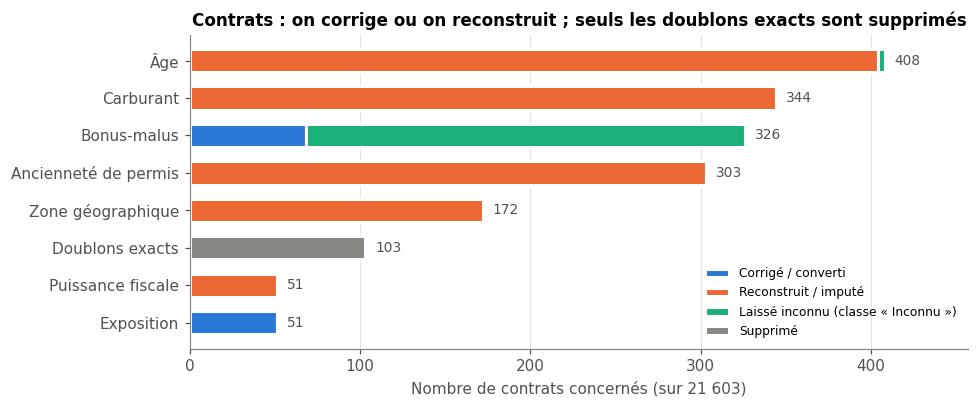

In [17]:
journal = pd.DataFrame({
    'Corrigé / converti'                 : {'Exposition': contrats['expo_corrigee'].sum(),
                                            'Bonus-malus': contrats['bm_corrige'].sum()},
    'Reconstruit / imputé'               : {'Âge': int(age_manq.sum()), 'Ancienneté de permis': int(anc_manq.sum()),
                                            'Puissance fiscale': imputes_vehicule['puissance_fiscale'],
                                            'Zone géographique': manquants_cat['zone_geo'],
                                            'Carburant': manquants_cat['carburant']},
    'Laissé inconnu (classe « Inconnu »)': {'Âge': int(contrats['age_inconnu'].sum()),
                                            'Bonus-malus': int(contrats['bonus_malus'].isna().sum())},
    'Supprimé'                           : {'Doublons exacts': n_contrats_depart - len(contrats)},
}).fillna(0).astype(int)
journal = journal.loc[journal.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 3.8))
gauche = np.zeros(len(journal))
for col, c in zip(journal.columns, [BLEU, ORANGE, AQUA, GRIS]):
    ax.barh(journal.index, journal[col], left=gauche, color=c, height=0.62, edgecolor='white',
            linewidth=2, label=col)
    gauche += journal[col].values
for i, tot in enumerate(gauche):
    ax.text(tot + 6, i, f'{int(tot)}', va='center', fontsize=9, color=ENCRE)
ax.set_xlabel(f'Nombre de contrats concernés (sur {n_contrats_depart:,})'.replace(',', ' '))
ax.set_xlim(0, gauche.max() * 1.12); ax.grid(axis='y', visible=False)
ax.set_title('Contrats : on corrige ou on reconstruit ; seuls les doublons exacts sont supprimés')
ax.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

---
## A.6 Étude de la base Sinistres

### A.6.1 Vue d'ensemble

In [18]:
apercu_s = pd.DataFrame({
    'type'       : sinistres.dtypes.astype(str),
    'n_manquants': sinistres.isna().sum(),
    'pct'        : (sinistres.isna().mean() * 100).round(2),
    'n_valeurs'  : sinistres.nunique()
})
print('Lignes :', len(sinistres))
print('id_sinistre dupliqués :', sinistres['id_sinistre'].duplicated().sum())
apercu_s

Lignes : 1320
id_sinistre dupliqués : 10


,type,n_manquants,pct,n_valeurs
id_sinistre,str,0,0.00,1310
id_police,str,0,0.00,1268
date_sinistre,object,0,0.00,526
nature_sinistre,str,10,0.76,14
montant_sinistre,str,20,1.52,1270
responsabilite_pct,float64,21,1.59,7
statut,str,10,0.76,4


### A.6.2 `montant_sinistre` — charge du sinistre

Montant indemnisé. C'est la variable la plus importante de cette base : elle servira de cible
au GLM sévérité et de base à la séparation entre sinistres attritionnels et graves.

**Attendu :** un nombre positif.
**À vérifier :** le type de la colonne. Certains montants sont stockés en texte avec un symbole
monétaire ou une virgule décimale ; une conversion directe les transformerait en valeurs
manquantes sans alerte, et des sinistres réels disparaîtraient du calcul de la charge.

In [19]:
print('Type de colonne :', sinistres['montant_sinistre'].dtype)
print('Exemples :', sinistres['montant_sinistre'].dropna().head(5).tolist())

# Nettoyage avant conversion : symbole monétaire, espaces (y compris insécables), virgule
m = (sinistres['montant_sinistre'].astype(str)
     .str.replace('€', '', regex=False)
     .str.replace('\u00a0', '', regex=False)
     .str.replace(' ', '', regex=False)
     .str.replace(',', '.', regex=False)
     .replace({'nan': None, '': None}))
montant = pd.to_numeric(m, errors='coerce')

print('\nManquants :', montant.isna().sum())
print('Négatifs  :', (montant < 0).sum())
print('Nuls      :', (montant == 0).sum())
print('\nDistribution des montants positifs :')
print(montant[montant > 0].describe(percentiles=[.5, .9, .99]).round(0).to_string())

Type de colonne : str
Exemples : ['1071.76', '607.18', '585.3', '378.93', '4084.1']

Manquants : 20
Négatifs  : 2
Nuls      : 6

Distribution des montants positifs :
count      1292.0
mean       7411.0
std       22664.0
min          87.0
50%         896.0
90%       21432.0
99%      101228.0
max      299141.0


### A.6.3 `date_sinistre` — date de survenance

Doit tomber pendant la période de couverture du contrat (contrôle en section 9) et sert au
découpage 2023 / 2024 pour la séparation Train / Test.

In [20]:
print('Types de valeurs rencontrés :')
print(sinistres['date_sinistre'].map(lambda v: type(v).__name__).value_counts().to_string())
dates_s = lit_dates(sinistres['date_sinistre'])

print('Dates non lisibles :', dates_s.isna().sum())
print('Plage :', dates_s.min(), '→', dates_s.max())
print(dates_s.dt.year.value_counts().sort_index().to_string())

Types de valeurs rencontrés :
date_sinistre
datetime    1300
str           20
Dates non lisibles : 0
Plage : 2023-01-02 00:00:00 → 2024-12-01 00:00:00
date_sinistre
2023    861
2024    459


### A.6.4 `nature_sinistre`, `statut` et `responsabilite_pct`

- **`nature_sinistre`** — type d'événement. Sert uniquement au contrôle de compatibilité avec
  la garantie souscrite ; n'entre dans aucun modèle.
- **`statut`** — `Ouvert` signifie que le dossier n'est pas clos : le montant est **provisoire**.
- **`responsabilite_pct`** — part de responsabilité de l'assuré, valeurs admises
  {0, 25, 50, 75, 100}. N'intervient pas dans le calcul de la prime pure.

In [21]:
for col in ['nature_sinistre', 'statut']:
    print(f'--- {col} ---')
    print(sinistres[col].value_counts(dropna=False).to_string())
    print()

resp = pd.to_numeric(sinistres['responsabilite_pct'], errors='coerce')
print('--- responsabilite_pct ---')
print(resp.value_counts(dropna=False).sort_index().to_string())
print('\nHors {0, 25, 50, 75, 100} :', (resp.notna() & ~resp.isin([0, 25, 50, 75, 100])).sum())

--- nature_sinistre ---
nature_sinistre
Bris de glace            349
Dégât matériel léger     316
Collision mineure        226
Vol partiel              167
Corporel grave            63
Vandalisme                60
Collision majeure         53
Vol total                 27
Incendie total            24
Catastrophe naturelle     15
NaN                       10
 Collision mineure         4
 Vol partiel               3
 Dégât matériel léger      2
 Incendie total            1

--- statut ---
statut
Clos      1045
Ouvert     250
NaN         10
clos         9
ouvert       6

--- responsabilite_pct ---
responsabilite_pct
0.0      211
25.0     115
50.0     205
75.0     126
100.0    636
120.0      1
150.0      5
NaN       21

Hors {0, 25, 50, 75, 100} : 6


---
## A.7 Problèmes identifiés — Base Sinistres

| Variable | Problème constaté | Décision |
| --- | --- | --- |
| `id_sinistre` | 10 identifiants dupliqués | **vérifié (A.8) : contenu identique sur toutes les colonnes** ; aucun sinistre n'est enregistré deux fois sous deux identifiants différents. Suppression d'une occurrence |
| `montant_sinistre` | montants stockés en texte (symbole monétaire, virgule décimale) | nettoyage du texte **avant** conversion, pour ne perdre aucun sinistre |
| `montant_sinistre` | montants manquants | **le sinistre est conservé** et compté dans la fréquence. Son montant est **revalorisé en partie B selon la nature du sinistre**, après avoir vérifié que le statut du dossier (clos / ouvert) ne change pas le niveau des montants |
| `montant_sinistre` | 2 montants négatifs, tous deux à −500 € exactement (dossiers clos, dont un vol total) | valeur codée, pas une erreur de signe (un vol total ne coûte pas 500 €) : traités comme des montants inconnus, puis revalorisés en partie B |
| `montant_sinistre` | montants nuls | **selon le statut** : un dossier clos à 0 € est un sinistre sans suite financière (exclu) ; un dossier ouvert à 0 € n'est pas encore évalué (revalorisé en partie B) |
| `date_sinistre` | 20 dates stockées en texte au format `aaaa/mm/jj` | lues avec ce format explicite (`lit_dates`). Une date réellement illisible serait imputée au milieu de la période de couverture de la police : le sinistre est réel, le supprimer baisserait la fréquence, et le découpage temporel exige une date |
| `nature_sinistre` | valeurs manquantes | modalité `Inconnu`. Pas d'imputation : une nature inventée déclencherait à tort le contrôle de garantie de la section 9 |
| `statut` | valeurs manquantes | modalité la plus fréquente |
| `responsabilite_pct` | valeurs manquantes ou hors référentiel | signalées sans correction : la variable n'entre pas dans la tarification |

**Règle générale :** aucun sinistre n'est supprimé pour cause de donnée manquante. Un sinistre
est un événement réel ; le retirer réduirait artificiellement la sinistralité du portefeuille.

---
## A.8 Corrections — Base Sinistres

In [22]:
dup = sinistres[sinistres['id_sinistre'].duplicated(keep=False)]
print('Identifiants de sinistre en double :', dup['id_sinistre'].nunique(), '| dont avec des informations différentes :',
      int((dup.astype(str).groupby('id_sinistre').nunique().max(axis=1) > 1).sum()))
n = len(sinistres)
sinistres = sinistres.drop_duplicates('id_sinistre', keep='first').copy()
print('Doublons supprimés :', n - len(sinistres), '| reste', len(sinistres))

# Montant : conversion propre, puis négatifs traités comme manquants
m = (sinistres['montant_sinistre'].astype(str)
     .str.replace('€', '', regex=False).str.replace('\u00a0', '', regex=False)
     .str.replace(' ', '', regex=False).str.replace(',', '.', regex=False)
     .replace({'nan': None, '': None}))
sinistres['montant_sinistre'] = pd.to_numeric(m, errors='coerce')
negatifs = sinistres['montant_sinistre'] < 0
sinistres.loc[negatifs, 'montant_sinistre'] = np.nan
print('Montants négatifs mis à NaN :', int(negatifs.sum()), '| valeurs :', m[negatifs].tolist())
print('Montants manquants au total :', sinistres['montant_sinistre'].isna().sum())
print('Montants nuls               :', (sinistres['montant_sinistre'] == 0).sum())

# Dates
sinistres['date_sinistre'] = lit_dates(sinistres['date_sinistre'])
print('Dates manquantes (imputées en section 9) :', sinistres['date_sinistre'].isna().sum())

# Nature et statut
sinistres['nature_sinistre'] = (sinistres['nature_sinistre'].astype('string')
                                .str.strip().str.title().fillna('Inconnu'))
sinistres['statut'] = sinistres['statut'].astype('string').str.strip().str.capitalize()
if sinistres['statut'].isna().any():
    mode_statut = sinistres['statut'].mode()[0]
    print('Statuts manquants remplacés par :', mode_statut)
    sinistres['statut'] = sinistres['statut'].fillna(mode_statut)

# Responsabilité : signalée, non corrigée
sinistres['responsabilite_pct'] = pd.to_numeric(sinistres['responsabilite_pct'], errors='coerce')
sinistres['resp_invalide'] = (sinistres['responsabilite_pct'].isna() |
                              ~sinistres['responsabilite_pct'].isin([0, 25, 50, 75, 100])).astype(int)
print('Responsabilités signalées :', sinistres['resp_invalide'].sum())

Identifiants de sinistre en double : 10 | dont avec des informations différentes : 0
Doublons supprimés : 10 | reste 1310
Montants négatifs mis à NaN : 2 | valeurs : ['-500', '-500']
Montants manquants au total : 22
Montants nuls               : 6
Dates manquantes (imputées en section 9) : 0
Statuts manquants remplacés par : Clos
Responsabilités signalées : 26


---
## A.9 Jointure Contrats × Sinistres

Trois contrôles avant de construire la base finale : le rattachement des sinistres à une
police, leur position dans la période de couverture, et la compatibilité entre la garantie
souscrite et la nature du sinistre.

### A.9.1 Sinistres sans contrat

Deux situations différentes : la police n'a **jamais** existé dans le fichier Contrats (anomalie
des données), ou elle existait mais a été supprimée lors du nettoyage (coût de notre propre
traitement, à chiffrer).

In [23]:
ids_propres = set(contrats['id_police'].astype(str).str.strip())
pol = sinistres['id_police'].astype(str).str.strip()

jamais_existe = ~pol.isin(ids_contrats_origine)
perdu_nettoyage = pol.isin(ids_contrats_origine) & ~pol.isin(ids_propres)
print('Polices inexistantes dès le départ  :', jamais_existe.sum())
print('Polices supprimées au nettoyage     :', perdu_nettoyage.sum(),
      '| charge concernée :', round(sinistres.loc[perdu_nettoyage, 'montant_sinistre'].sum(), 0))

n = len(sinistres)
sinistres = sinistres[~(jamais_existe | perdu_nettoyage)].copy()
print('Sinistres supprimés :', n - len(sinistres), '| reste', len(sinistres))

Polices inexistantes dès le départ  : 6
Polices supprimées au nettoyage     : 0 | charge concernée : 0.0
Sinistres supprimés : 6 | reste 1304


### A.9.2 Période de couverture

La fin de la période de couverture se déduit de la date d'effet et de l'exposition. Les dates
manquantes sont imputées au milieu de cette période ; elles ne sont donc pas testées ensuite.

In [24]:
contrats['date_fin_couverture'] = (contrats['date_effet_contrat'] +
    pd.to_timedelta(contrats['duree_exposition'] * 365.25, unit='D')).dt.normalize()
ref = contrats.set_index('id_police')

debut = sinistres['id_police'].map(ref['date_effet_contrat'])
fin   = sinistres['id_police'].map(ref['date_fin_couverture'])

manquantes = sinistres['date_sinistre'].isna()
sinistres.loc[manquantes, 'date_sinistre'] = (
    debut[manquantes] + (fin[manquantes] - debut[manquantes]) / 2).dt.normalize()
print('Dates imputées :', manquantes.sum(), '| restantes :', sinistres['date_sinistre'].isna().sum())

tolerance = pd.Timedelta(days=2)
hors = ((sinistres['date_sinistre'] < debut - tolerance) |
        (sinistres['date_sinistre'] > fin + tolerance)) & ~manquantes
sinistres['hors_periode'] = hors.fillna(False).astype(int)
print('Sinistres hors période de couverture :', int(hors.sum()))

Dates imputées : 0 | restantes : 0
Sinistres hors période de couverture : 1


### A.9.3 Compatibilité garantie × nature du sinistre

Une formule **Tiers** ne couvre que les dommages causés aux tiers : un vol, un incendie, un
bris de glace, une catastrophe naturelle ou un acte de vandalisme sur le véhicule de l'assuré
n'y sont pas indemnisables. Les collisions, dégâts matériels et corporels peuvent relever de la
responsabilité civile comme des dommages propres : ils restent compatibles avec toutes les
formules, afin de ne signaler que les incompatibilités certaines.

In [25]:
non_couvert_tiers = ['Vol Total', 'Vol Partiel', 'Incendie Total',
                     'Bris De Glace', 'Catastrophe Naturelle', 'Vandalisme']
couverture = sinistres['id_police'].map(ref['type_couverture'])
sinistres['hors_garantie'] = ((couverture == 'Tiers') &
                              sinistres['nature_sinistre'].isin(non_couvert_tiers)).astype(int)
print('Sinistres non couverts par leur formule :', sinistres['hors_garantie'].sum())
pd.crosstab(sinistres['nature_sinistre'], couverture, margins=True)

Sinistres non couverts par leur formule : 155


id_police,Tiers,Tiers étendu,Tous risques,All
nature_sinistre,,,,
Bris De Glace,95,96,152,343
Catastrophe Naturelle,3,7,5,15
Collision Majeure,14,16,22,52
Collision Mineure,68,53,106,227
Corporel Grave,16,18,28,62
Dégât Matériel Léger,73,97,143,313
Incendie Total,7,6,12,25
Inconnu,4,3,3,10
Vandalisme,11,24,25,60


### A.9.4 Base agrégée par police

Une ligne par police, **toutes les polices comprises**, y compris celles sans sinistre : un
modèle de fréquence a besoin des zéros. Les sinistres à montant nul et ceux survenus hors de
la période de couverture sont exclus de l'agrégation.

Colonnes produites pour les binômes suivants : `nb_sinistres` (cible du GLM fréquence),
`nb_sinistres_cout` (pondération du GLM sévérité), `charge_totale`, `log_exposition` (offset),
et le découpage 2023 / 2024 pour la séparation Train / Test.

In [26]:
retenus = sinistres[(sinistres['montant_sinistre'].isna() | (sinistres['montant_sinistre'] != 0))
                    & (sinistres['hors_periode'] == 0)].copy()
retenus['montant_valide'] = retenus['montant_sinistre'].where(retenus['montant_sinistre'] > 0)
print('Sinistres retenus pour l\'agrégation :', len(retenus), 'sur', len(sinistres))

resume = retenus.groupby('id_police').agg(
    nb_sinistres      = ('id_sinistre', 'count'),
    nb_sinistres_cout = ('montant_valide', 'count'),
    charge_totale     = ('montant_valide', 'sum')).reset_index()

base = contrats.merge(resume, on='id_police', how='left')   # jointure à GAUCHE : on garde tout
base[['nb_sinistres', 'nb_sinistres_cout']] = base[['nb_sinistres', 'nb_sinistres_cout']].fillna(0).astype(int)
base['charge_totale']  = base['charge_totale'].fillna(0.0)
base['log_exposition'] = np.log(base['duree_exposition'])

# Découpage par année civile
debut, fin = base['date_effet_contrat'], base['date_fin_couverture']
for an in [2023, 2024]:
    d0, d1 = pd.Timestamp(f'{an}-01-01'), pd.Timestamp(f'{an + 1}-01-01')
    part = ((fin.clip(upper=d1) - debut.clip(lower=d0)).dt.days.clip(lower=0)
            / (fin - debut).dt.days.clip(lower=1))
    base[f'expo_{an}'] = (part * base['duree_exposition']).round(6)
    sin_an = retenus[retenus['date_sinistre'].dt.year == an]
    base[f'nb_sin_{an}'] = base['id_police'].map(sin_an.groupby('id_police').size()).fillna(0).astype(int)

# Classes de risque (un tarif se lit en classes, pas en valeurs continues)
base['classe_age']       = pd.cut(base['age_conducteur'], [17, 25, 35, 50, 65, 200],
                                  labels=['18-25', '26-35', '36-50', '51-65', '66+']).astype(str)
base['classe_bm']        = pd.cut(base['bonus_malus'], [0.49, 0.80, 1.00, 1.25, 3.50],
                                  labels=['<0,80', '0,80-1,00', '1,00-1,25', '>1,25']).astype(str)
base['classe_puissance'] = pd.cut(base['puissance_fiscale'], [0, 5, 7, 9, 100],
                                  labels=['<=5', '6-7', '8-9', '>=10']).astype(str)
base['classe_vehic_age'] = pd.cut(base['age_vehicule'], [-1, 2, 5, 10, 100],
                                  labels=['0-2', '3-5', '6-10', '11+']).astype(str)
for col in ['classe_age', 'classe_bm']:
    base[col] = base[col].fillna('Inconnu').replace({'nan': 'Inconnu'})
print('Classes « Inconnu » : âge', int((base['classe_age'] == 'Inconnu').sum()),
      '| bonus-malus', int((base['classe_bm'] == 'Inconnu').sum()))
print('Base agrégée :', base.shape)

Sinistres retenus pour l'agrégation : 1297 sur 1304
Classes « Inconnu » : âge 4 | bonus-malus 258
Base agrégée : (21500, 30)


### A.9.5 Vérification finale et export

In [27]:
verifs = {
    'lignes identiques aux contrats'      : int(len(base) != len(contrats)),
    'id_police dupliqué'                  : base['id_police'].duplicated().sum(),
    'exposition manquante ou nulle'       : (base['duree_exposition'].isna() |
                                             (base['duree_exposition'] <= 0)).sum(),
    'charge sans sinistre'                : ((base['charge_totale'] > 0) &
                                             (base['nb_sinistres'] == 0)).sum(),
    'total des sinistres incohérent'      : int(base['nb_sinistres'].sum() != len(retenus)),
    'découpage annuel incohérent'         : ((base['expo_2023'] + base['expo_2024']
                                              - base['duree_exposition']).abs() > 0.01).sum(),
}
for nom, n in verifs.items():
    print(f'  {"OK   " if n == 0 else "RESTE"}  {nom:<38} {int(n):>5}')

sinistres.to_csv('sinistres_propres.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
base.to_csv('base_agregee.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')

print(f'\nContrats  : {n_contrats_depart:,} → {len(contrats):,}')
print(f'Sinistres : {n_sinistres_depart:,} → {len(sinistres):,} (dont {len(retenus):,} retenus)')
print(f'Exposition totale : {base["duree_exposition"].sum():,.1f} années-police')
print(f'  2023 : {base["expo_2023"].sum():,.1f}  |  2024 : {base["expo_2024"].sum():,.1f}')
print(f'Sinistres : {int(base["nb_sinistres"].sum()):,} '
      f'(2023 : {int(base["nb_sin_2023"].sum()):,} | 2024 : {int(base["nb_sin_2024"].sum()):,})')
print(f'Charge totale : {base["charge_totale"].sum():,.0f}')
print('\nFichiers écrits : contrats_propres.csv, sinistres_propres.csv, base_agregee.csv')

  OK     lignes identiques aux contrats             0
  OK     id_police dupliqué                         0
  OK     exposition manquante ou nulle              0
  OK     charge sans sinistre                       0
  OK     total des sinistres incohérent             0
  OK     découpage annuel incohérent                0



Contrats  : 21,603 → 21,500
Sinistres : 1,320 → 1,304 (dont 1,297 retenus)
Exposition totale : 12,359.2 années-police
  2023 : 8,194.5  |  2024 : 4,164.7
Sinistres : 1,297 (2023 : 849 | 2024 : 448)
Charge totale : 9,486,212

Fichiers écrits : contrats_propres.csv, sinistres_propres.csv, base_agregee.csv


---
### Bilan de la partie A — points repris dans la suite

- Seuls les **doublons exacts** sont retirés (vérifiés colonne par colonne) : les expositions codées
  sont corrigées et les âges reconstruits, sans supprimer de contrat.
- `duree_exposition` est un **offset**, pas une variable explicative ; `log_exposition` est
  déjà calculé dans la base agrégée.
- `age_conducteur` et `anciennete_permis` sont presque identiques à 20 ans près : **une seule des
  deux** dans un même GLM (on utilise `classe_age`).
- Les âges et bonus-malus impossibles à reconstruire forment une modalité `Inconnu` des classes
  tarifaires : le GLM estime leur risque au lieu qu'on invente une valeur.
- Les montants manquants, négatifs codés ou non évalués sont revalorisés en partie B, selon la
  nature du sinistre et après contrôle de l'effet du statut du dossier.
- Relecture : `pd.read_csv('base_agregee.csv', parse_dates=['date_effet_contrat',
  'date_fin_couverture'])`.

---
# Partie B — Séparation des sinistres attritionnels et graves

**Entrées :** `sinistres_propres.csv`, `base_agregee.csv` (produits par la partie A).
**Sorties :** `sinistres_B.csv` (sinistre par sinistre, avec `sinistre_grave`) et `base_B.csv`
(une ligne par police, charges et effectifs séparés attritionnels / graves).

1. Reprise des sorties de la partie A
2. Étude des montants avant séparation
3. Problèmes identifiés
4. Corrections — périmètre de tarification et fiabilité des montants
5. Méthode Peaks Over Threshold (POT)
6. Croisement du seuil avec la nature des sinistres
7. Comparaison de plusieurs méthodes de séparation
8. Variable `sinistre_grave` : effectifs et part de charge
9. Agrégation par police
10. Vérification et export
11. Justification du seuil retenu

## B.1 Reprise des sorties de la partie A

On relit les fichiers exportés par la partie A plutôt que les objets en mémoire : la partie B
travaille ainsi exactement sur les données livrées, et peut être relancée seule.

In [28]:
sinistres = pd.read_csv('sinistres_propres.csv', parse_dates=['date_sinistre'])
base = pd.read_csv('base_agregee.csv', parse_dates=['date_effet_contrat', 'date_fin_couverture'])
print('Sinistres :', sinistres.shape, '| Base agrégée :', base.shape)

# Reprise : le périmètre d'agrégation de la partie A doit redonner le total de la base agrégée
m = sinistres['montant_sinistre']
retenus_A = (m.isna() | (m != 0)) & (sinistres['hors_periode'] == 0)
print('Sinistres retenus en partie A :', int(retenus_A.sum()),
      '| total nb_sinistres de la base :', int(base['nb_sinistres'].sum()))
print('Sinistres rattachés à une police absente de la base :',
      int((~sinistres['id_police'].isin(base['id_police'])).sum()))

Sinistres : (1304, 10) | Base agrégée : (21500, 30)
Sinistres retenus en partie A : 1297 | total nb_sinistres de la base : 1297
Sinistres rattachés à une police absente de la base : 0


## B.2 Étude des montants avant séparation

### B.2.1 Distribution des montants et nature des sinistres

La partie A a observé une séparation nette entre sinistres légers (~1 000 €) et graves (dizaines
de milliers d'€). On la mesure ici : on cherche le plus grand « trou » dans la distribution des
montants, sur une échelle logarithmique (les montants couvrent plus de trois ordres de grandeur).

In [29]:
natures_graves = ['Collision Majeure', 'Corporel Grave', 'Incendie Total', 'Vol Total',
                  'Catastrophe Naturelle']
m = sinistres['montant_sinistre']
pos = sinistres[m > 0]

print('Montants strictement positifs :', len(pos))
print(pos['montant_sinistre'].describe(percentiles=[.5, .75, .85, .9, .95, .99]).round(0).to_string())

# Plus grands écarts entre deux montants consécutifs (en log)
xs = np.sort(pos['montant_sinistre'].values)
ecarts = pd.DataFrame({'montant_bas': xs[:-1], 'montant_haut': xs[1:],
                       'rapport': xs[1:] / xs[:-1]}).nlargest(3, 'rapport')
print('\nLes trois plus grands écarts entre montants consécutifs :')
print(ecarts.round(2).to_string(index=False))

print('\nMontant par nature :')
print(sinistres.groupby('nature_sinistre')['montant_sinistre']
      .agg(['count', 'min', 'median', 'max']).round(0).sort_values('median').to_string())

Montants strictement positifs : 1277
count      1277.0
mean       7430.0
std       22746.0
min          87.0
50%         896.0
75%        1651.0
85%        3419.0
90%       21458.0
95%       44829.0
99%      101283.0
max      299141.0

Les trois plus grands écarts entre montants consécutifs :
 montant_bas  montant_haut  rapport
     5970.25      12000.00     2.01
       88.99        118.50     1.33
   212744.90     282958.19     1.33

Montant par nature :
                       count      min   median       max
nature_sinistre                                         
Collision Mineure        225      0.0    733.0    4930.0
Vandalisme                59      0.0    737.0    3357.0
Bris De Glace            335      0.0    746.0    5970.0
Vol Partiel              168      0.0    780.0    3861.0
Dégât Matériel Léger     309      0.0    808.0    5400.0
Inconnu                   10    352.0    872.0  128603.0
Catastrophe Naturelle     15  12000.0  22422.0   92702.0
Collision Majeure         5

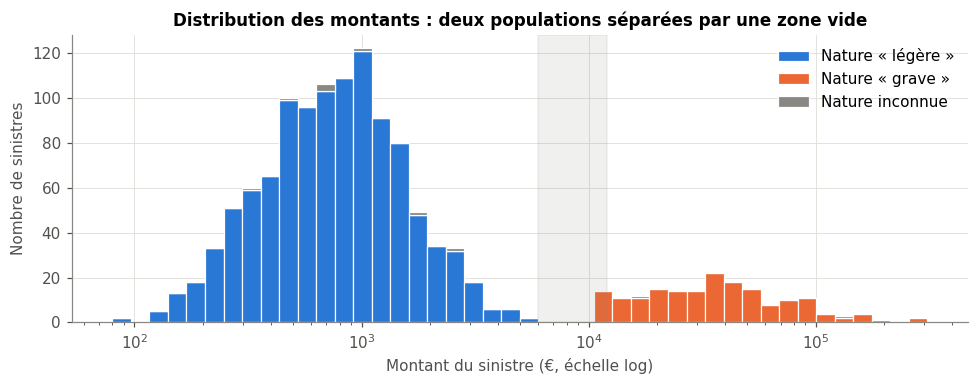

In [30]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(np.log10(80), np.log10(310_000), 45)
leg = pos[~pos['nature_sinistre'].isin(natures_graves + ['Inconnu'])]['montant_sinistre']
grv = pos[pos['nature_sinistre'].isin(natures_graves)]['montant_sinistre']
inc = pos[pos['nature_sinistre'] == 'Inconnu']['montant_sinistre']
ax.hist([leg, grv, inc], bins=bins, stacked=True, color=[BLEU, ORANGE, GRIS],
        edgecolor='white', linewidth=0.8,
        label=['Nature « légère »', 'Nature « grave »', 'Nature inconnue'])
ax.set_xscale('log')
ax.axvspan(ecarts.iloc[0]['montant_bas'], ecarts.iloc[0]['montant_haut'], color=GRIS, alpha=0.12)
ax.set_xlabel('Montant du sinistre (€, échelle log)')
ax.set_ylabel('Nombre de sinistres')
ax.set_title('Distribution des montants : deux populations séparées par une zone vide')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### B.2.2 Valeurs répétées

Un montant continu (réparation, indemnisation corporelle) ne se répète pratiquement jamais au
centime près. Une valeur ronde répétée signale une **valeur conventionnelle** (forfait, évaluation
par défaut), qui n'est pas un coût observé. Si ces valeurs étaient des forfaits provisoires
posés à l'ouverture du dossier, elles se concentreraient sur les dossiers `Ouvert` : on vérifie
leur répartition par statut, nature, date et responsabilité.

In [31]:
rep = pos['montant_sinistre'].value_counts()
print('Montants présents plus de 2 fois :')
print(rep[rep > 2].to_string())

forfait = sinistres['montant_sinistre'] == 12000
print('\nSinistres à 12 000,00 € exactement, par nature et statut :')
print(pd.crosstab(sinistres.loc[forfait, 'nature_sinistre'], sinistres.loc[forfait, 'statut'],
                  margins=True).to_string())
print('\nDétail (trié par date) :')
print(sinistres.loc[forfait, ['id_sinistre', 'date_sinistre', 'nature_sinistre', 'statut',
                              'responsabilite_pct']].sort_values('date_sinistre').to_string(index=False))
autres = pos.loc[pos['nature_sinistre'].isin(natures_graves) & ~forfait, 'montant_sinistre']
print('\nCoût médian des autres sinistres de ces natures :', round(autres.median(), 0))
print(f'Sensibilité — coût moyen des sinistres de nature grave : {autres.mean():,.0f} € sans les 12 valeurs, '
      f'{pd.concat([autres, sinistres.loc[forfait, "montant_sinistre"]]).mean():,.0f} € avec')

Montants présents plus de 2 fois :
montant_sinistre
12000.0    12

Sinistres à 12 000,00 € exactement, par nature et statut :
statut                 Clos  Ouvert  All
nature_sinistre                         
Catastrophe Naturelle     2       0    2
Collision Majeure         1       1    2
Corporel Grave            3       4    7
Incendie Total            0       1    1
All                       6       6   12

Détail (trié par date) :
id_sinistre date_sinistre       nature_sinistre statut  responsabilite_pct
  SIN500912    2023-03-19        Incendie Total Ouvert                75.0
  SIN501239    2023-04-13 Catastrophe Naturelle   Clos               100.0
  SIN501036    2023-05-07        Corporel Grave Ouvert                50.0
  SIN501245    2023-05-12     Collision Majeure   Clos               100.0
  SIN500280    2023-07-06        Corporel Grave   Clos               100.0
  SIN500378    2023-08-20        Corporel Grave Ouvert                50.0
  SIN501234    2023-09-07     Collis

### B.2.3 Statut des dossiers et niveau des montants

Un dossier `Ouvert` porte une charge **provisoire**. Deux questions :
1. les graves sont-ils plus souvent ouverts que les attritionnels ?
2. à nature égale, le montant d'un dossier ouvert est-il plus faible que celui d'un dossier clos ?
   Si oui, il faudrait le corriger par un coefficient de développement ; sinon, un montant manquant
   peut être revalorisé par le coût moyen de sa nature, quel que soit le statut.

In [32]:
classe_nature = np.where(sinistres['nature_sinistre'].isin(natures_graves), 'nature grave',
                np.where(sinistres['nature_sinistre'] == 'Inconnu', 'inconnue', 'nature légère'))
t = pd.crosstab(classe_nature, sinistres['statut'])
t['% ouverts'] = (t['Ouvert'] / t.sum(axis=1) * 100).round(1)
print(t.to_string())

clos_sans = (sinistres['statut'] == 'Clos') & sinistres['montant_sinistre'].isna()
print('\nDossiers clos sans montant :', int(clos_sans.sum()))
print(sinistres.loc[clos_sans, 'nature_sinistre'].value_counts().to_string())

statut         Clos  Ouvert  % ouverts
row_0                                 
inconnue          7       3       30.0
nature grave     97      84       46.4
nature légère   950     163       14.6

Dossiers clos sans montant : 18
nature_sinistre
Bris De Glace           7
Dégât Matériel Léger    4
Collision Mineure       2
Vol Total               2
Vol Partiel             1
Incendie Total          1
Corporel Grave          1


In [33]:
# Montants observés (hors valeurs à 12 000 €) : ouverts vs clos, nature par nature
obs = sinistres[(sinistres['montant_sinistre'] > 0) & (sinistres['montant_sinistre'] != 12000)]
lignes = []
for nat, g in obs.groupby('nature_sinistre'):
    clos_, ouv_ = g.loc[g['statut'] == 'Clos', 'montant_sinistre'], g.loc[g['statut'] == 'Ouvert', 'montant_sinistre']
    if len(clos_) >= 3 and len(ouv_) >= 3:
        lignes.append({'nature': nat, 'n clos': len(clos_), 'n ouverts': len(ouv_),
                       'médiane clos': clos_.median(), 'médiane ouverts': ouv_.median(),
                       'ouverts / clos (moyennes)': ouv_.mean() / clos_.mean(),
                       'p Mann-Whitney': stats.mannwhitneyu(clos_, ouv_).pvalue})
comp_statut = pd.DataFrame(lignes).set_index('nature')

grp = np.where(obs['nature_sinistre'].isin(natures_graves), 'natures graves', 'natures légères')
for nom in ['natures légères', 'natures graves']:
    g = obs[grp == nom]
    c_, o_ = g.loc[g['statut'] == 'Clos', 'montant_sinistre'], g.loc[g['statut'] == 'Ouvert', 'montant_sinistre']
    print(f'{nom:<16}: médiane clos {c_.median():>7,.0f} € | ouverts {o_.median():>7,.0f} € | '
          f'p Mann-Whitney = {stats.mannwhitneyu(c_, o_).pvalue:.3f}')
comp_statut.round(3)

natures légères : médiane clos     767 € | ouverts     713 € | p Mann-Whitney = 0.953
natures graves  : médiane clos  37,768 € | ouverts  35,002 € | p Mann-Whitney = 0.623


,n clos,n ouverts,médiane clos,médiane ouverts,ouverts / clos (moyennes),p Mann-Whitney
nature,,,,,,
Bris De Glace,278,56,744.990,780.930,0.943,0.748
Catastrophe Naturelle,10,3,24883.980,27406.520,0.917,0.937
Collision Majeure,25,24,33798.730,38199.240,1.585,0.363
Collision Mineure,193,31,752.130,629.150,0.981,0.323
Corporel Grave,28,26,42190.525,36865.735,0.894,0.382
Dégât Matériel Léger,269,39,812.270,762.680,0.997,0.839
Incendie Total,9,14,52621.600,36470.660,0.906,0.329
Inconnu,7,3,691.450,18278.740,45.403,0.267
Vandalisme,53,5,736.520,1276.600,1.939,0.146


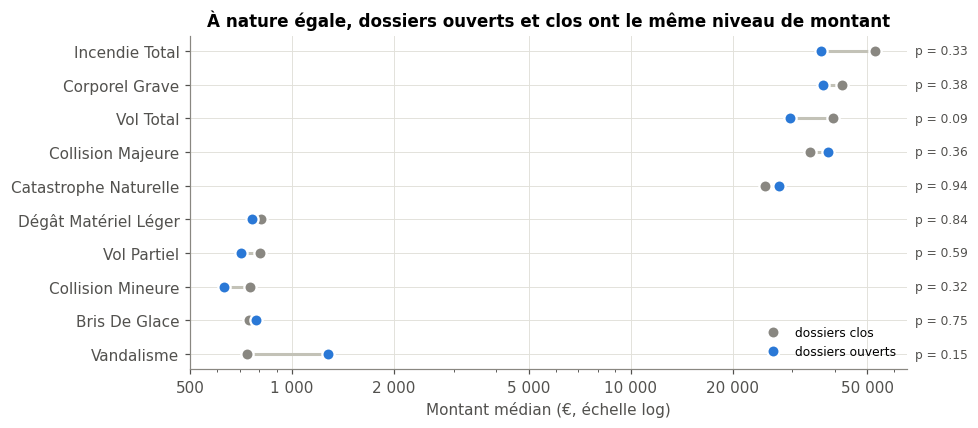

In [34]:
cs = comp_statut.drop(index='Inconnu', errors='ignore').sort_values('médiane clos')
y = np.arange(len(cs))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hlines(y, cs[['médiane clos', 'médiane ouverts']].min(axis=1), cs[['médiane clos', 'médiane ouverts']].max(axis=1),
          color='#c3c2b7', lw=2)
ax.plot(cs['médiane clos'], y, 'o', color=GRIS, ms=8, mec='white', mew=1.5, label='dossiers clos')
ax.plot(cs['médiane ouverts'], y, 'o', color=BLEU, ms=8, mec='white', mew=1.5, label='dossiers ouverts')
for yi, pv in zip(y, cs['p Mann-Whitney']):
    ax.text(1.01, yi, f'p = {pv:.2f}', transform=ax.get_yaxis_transform(), va='center', fontsize=8, color=ENCRE)
ax.set_yticks(y, cs.index); ax.set_xscale('log')
ax.set_xticks([500, 1000, 2000, 5000, 10000, 20000, 50000], ['500', '1 000', '2 000', '5 000', '10 000', '20 000', '50 000'])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('Montant médian (€, échelle log)')
ax.set_title('À nature égale, dossiers ouverts et clos ont le même niveau de montant')
ax.legend(frameon=False, loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.** À nature égale, les montants des dossiers ouverts ne sont pas significativement
différents de ceux des dossiers clos : aucun test n'est significatif à 5 %. Les montants provisoires
sont donc déjà évalués à leur niveau final moyen, et **aucun coefficient de développement n'est
justifié**. Conséquence pour le traitement : un montant inconnu (manquant, codé à −500 €, ou nul sur un
dossier encore ouvert) est revalorisé par le **coût moyen observé de sa nature**, dossiers clos et
ouverts confondus.

### B.2.4 Sinistres incompatibles avec la formule Tiers (repris de la partie A, § 9.3)

La partie A a signalé ces sinistres (`hors_garantie = 1`) sans les exclure de l'agrégation.
On retrace d'abord leur nombre depuis les fichiers bruts, puis on mesure leur poids, et enfin on regarde
si leur fréquence dépend de la formule souscrite.

In [35]:
# Traçabilité : d'où vient l'écart entre le décompte brut et celui de la partie A ?
brut_c = pd.read_excel('groupe3_base1_contrats.xlsx')
brut_s = pd.read_excel('groupe3_base2_sinistres.xlsx')
couv_brut = (brut_c.drop_duplicates('id_police').set_index('id_police')['type_couverture']
             .astype(str).str.strip()
             .replace({'Tiers Etendu': 'Tiers étendu', 'Tiers etendu': 'Tiers étendu', 'Tous Risques': 'Tous risques'}))
nc_tiers = ['Vol Total', 'Vol Partiel', 'Incendie Total', 'Bris De Glace', 'Catastrophe Naturelle', 'Vandalisme']
def hors_garantie_brut(df):
    return ((df['id_police'].map(couv_brut) == 'Tiers')
            & df['nature_sinistre'].astype(str).str.strip().str.title().isin(nc_tiers))
sd = brut_s.drop_duplicates('id_sinistre')
print('Hors garantie, fichiers bruts                      :', int(hors_garantie_brut(brut_s).sum()))
print('  après suppression des doublons de sinistres      :', int(hors_garantie_brut(sd).sum()))
print('  après retrait des polices supprimées en partie A :',
      int((hors_garantie_brut(sd) & sd['id_police'].isin(base['id_police'])).sum()))
print('Partie A (hors_garantie = 1)                       :', int(sinistres['hors_garantie'].sum()))
print()

hg = sinistres['hors_garantie'] == 1
print('Sinistres hors garantie :', int(hg.sum()),
      f'| charge : {sinistres.loc[hg, "montant_sinistre"].sum():,.0f} €',
      f'({sinistres.loc[hg, "montant_sinistre"].sum() / sinistres["montant_sinistre"].sum() * 100:.1f} % de la charge)')
print(sinistres.loc[hg].groupby('nature_sinistre')['montant_sinistre']
      .agg(['count', 'sum']).round(0).to_string())

non_couvert_tiers = ['Vol Total', 'Vol Partiel', 'Incendie Total', 'Bris De Glace',
                     'Catastrophe Naturelle', 'Vandalisme']
formule = sinistres['id_police'].map(base.set_index('id_police')['type_couverture'])
nb = sinistres[sinistres['nature_sinistre'].isin(non_couvert_tiers)].groupby(formule).size()
expo = base.groupby('type_couverture')['duree_exposition'].sum()
print('\nFréquence annuelle de ces natures selon la formule souscrite :')
print((nb / expo).round(4).to_string())

Hors garantie, fichiers bruts                      : 158
  après suppression des doublons de sinistres      : 155
  après retrait des polices supprimées en partie A : 155
Partie A (hors_garantie = 1)                       : 155

Sinistres hors garantie : 155 | charge : 713,325 € (7.5 % de la charge)
                       count       sum
nature_sinistre                       
Bris De Glace             93   91923.0
Catastrophe Naturelle      3   75063.0
Incendie Total             7  364125.0
Vandalisme                11    9111.0
Vol Partiel               36   32564.0
Vol Total                  3  140539.0

Fréquence annuelle de ces natures selon la formule souscrite :
id_police
Tiers           0.0507
Tiers étendu    0.0547
Tous risques    0.0504


---
## B.3 Problèmes identifiés

| Variable / objet | Problème constaté | Décision |
| --- | --- | --- |
| `montant_sinistre` | 12 sinistres valent exactement 12 000,00 €, tous de nature grave, alors que le coût médian de ces natures est d'environ 36 000 € | **montant jugé non fiable** : douze valeurs identiques au centime sont incompatibles avec un coût continu, et elles ne dépendent pas du statut (6 clos, 6 ouverts, § 2.2). Le sinistre est conservé ; son montant est **revalorisé par le coût moyen observé de sa nature** (indicateur `montant_forfait`). La valeur brute reste dans l'échantillon du seuil : elle est au-dessus de tout seuil de la zone vide, donc sans effet sur la partition |
| `montant_sinistre` manquant | 21 sinistres (18 clos, 3 ouverts), dont les 2 montants codés à −500 € | **revalorisés par le coût moyen de leur nature**, le statut n'ayant pas d'effet sur le niveau des montants (§ 2.3). Indicateur `montant_impute`. Ils sont exclus de l'échantillon du seuil : une valeur reconstruite ne doit pas servir à estimer la queue de distribution |
| `montant_sinistre` = 0 | 5 dossiers clos, 1 dossier ouvert | **selon le statut** : dossier clos à 0 € = sinistre sans suite, exclu de la fréquence et du coût (`sans_suite = 1`) ; dossier ouvert à 0 € = pas encore évalué, revalorisé comme un montant manquant |
| `statut` × `montant_sinistre` | 18 dossiers `Clos` sans montant et 5 dossiers `Clos` à 0 € | indicateur **`anomalie_gestion = 1`** (23 lignes) : un dossier clos devrait porter un montant réglé connu. Traçabilité seulement |
| `statut` | 47 % des sinistres de nature grave sont encore ouverts, contre 15 % des légers | **pas de correction** : à nature égale, les montants ouverts ne sont pas plus faibles que les montants clos (§ 2.3) |
| Échantillon du seuil | le seuil doit être estimé sur des coûts réellement observés | `montants_seuil` est reconstruit depuis le fichier brut avec les règles de la partie A : **tous les montants strictement positifs des sinistres non orphelins (n = 1 277)**, y compris hors garantie (le seuil est une propriété de la distribution des coûts, pas du contrat) |
| `hors_garantie` | 155 sinistres (713 325 €, 7,5 % de la charge) d'une nature non couverte par la formule Tiers souscrite | **exclus du périmètre de tarification** (`perimetre_tarif = 0`), conservés dans le fichier : l'assureur ne les doit pas contractuellement. Leur fréquence est la même quelle que soit la formule (§ 2.4) : ce sont des déclarations enregistrées avant le contrôle de garantie |
| Séparation attritionnels / graves | aucune variable ne l'indique | construction de `sinistre_grave` par la méthode POT (section 5), croisée avec la nature (section 6) |

**Règle.** Toutes les méthodes de seuil sont calculées **uniquement** sur `montants_seuil`
(montants observés). Les montants revalorisés et le périmètre de tarification n'interviennent
qu'à partir de la section 8.

---
## B.4 Corrections — échantillon du seuil, périmètre et indicateurs

In [36]:
s = sinistres.copy()
m = s['montant_sinistre']

# Étape 1 — échantillon d'estimation du seuil, reconstruit depuis le fichier brut
# (mêmes règles que la partie A : doublons, nettoyage du texte, négatifs → manquant)
brut = pd.read_excel('groupe3_base2_sinistres.xlsx', dtype={'montant_sinistre': str})
brut = brut.drop_duplicates('id_sinistre').copy()
txt = (brut['montant_sinistre'].astype(str)
       .str.replace('€', '', regex=False).str.replace(' ', '', regex=False)
       .str.replace(' ', '', regex=False).str.replace(',', '.', regex=False)
       .replace({'nan': None, '': None}))
brut['montant'] = pd.to_numeric(txt, errors='coerce')
brut.loc[brut['montant'] < 0, 'montant'] = np.nan
brut['nature_sinistre'] = brut['nature_sinistre'].astype('string').str.strip().str.title().fillna('Inconnu')
ids_origine = set(brut_c['id_police'].astype(str).str.strip())
non_orphelin = brut['id_police'].astype(str).str.strip().isin(ids_origine)

montants_seuil = brut.loc[non_orphelin & (brut['montant'] > 0),
                          ['id_sinistre', 'id_police', 'nature_sinistre', 'montant']].copy()
montants_seuil['dans_fichier_A'] = montants_seuil['id_sinistre'].isin(s['id_sinistre'])
print('Sinistres après dédoublonnage :', len(brut), '| orphelins :', int((~non_orphelin).sum()),
      '| non orphelins :', int(non_orphelin.sum()))
nb_nul, nb_nan = int((brut.loc[non_orphelin, 'montant'] == 0).sum()), int(brut.loc[non_orphelin, 'montant'].isna().sum())
print(f'  montants > 0 : {len(montants_seuil)} | nuls : {nb_nul} | manquants : {nb_nan}')
print('  dont sinistres absents de sinistres_propres (polices supprimées en A) :',
      int((~montants_seuil['dans_fichier_A']).sum()))

# Étape 2 — indicateurs
s['montant_forfait']  = (m == 12000).astype(int)
s['anomalie_gestion'] = ((s['statut'] == 'Clos') & (m.isna() | (m == 0))).astype(int)
statut_brut_manquant = s['id_sinistre'].map(brut.set_index('id_sinistre')['statut'].isna())
# Montant observé et fiable : strictement positif et non forfaitaire
s['montant_fiable'] = m.where((m > 0) & (s['montant_forfait'] == 0))

# Étape 3 — traitement des montants selon le statut du dossier et la nature du sinistre
s['sans_suite'] = ((m == 0) & (s['statut'] == 'Clos')).astype(int)            # clos à 0 € : sans suite
a_revaloriser = m.isna() | (s['montant_forfait'] == 1) | ((m == 0) & (s['statut'] == 'Ouvert'))
cout_nature = s.groupby('nature_sinistre')['montant_fiable'].mean()          # clos + ouverts (§ 2.3)
s['montant_impute'] = a_revaloriser.astype(int)
s['montant_retenu'] = m.where(~a_revaloriser, s['nature_sinistre'].map(cout_nature))
s.loc[s['sans_suite'] == 1, 'montant_retenu'] = 0.0

# Périmètre de tarification : sans suite, hors période et hors garantie exclus
s['perimetre_tarif'] = ((s['sans_suite'] == 0) & (s['hors_periode'] == 0)
                        & (s['hors_garantie'] == 0)).astype(int)

rev = s[a_revaloriser]
print('\nMontants revalorisés par le coût moyen de leur nature :')
print(pd.DataFrame({'revalorisés': rev.groupby('nature_sinistre').size(),
                    'dont 12 000 €': rev.groupby('nature_sinistre')['montant_forfait'].sum(),
                    'coût moyen utilisé (€)': cout_nature.reindex(rev['nature_sinistre'].unique()).round(0)}).to_string())
print('Sinistres sans suite (clos à 0 €) :', int(s['sans_suite'].sum()))

print('\nanomalie_gestion = 1                   :', s['anomalie_gestion'].sum(),
      '| dont statut imputé « Clos » en partie A :', int((s['anomalie_gestion'].astype(bool) & statut_brut_manquant).sum()))
print('Montants à 12 000 € revalorisés        :', s['montant_forfait'].sum())
print('Sinistres dans le périmètre tarifaire   :', s['perimetre_tarif'].sum(), 'sur', len(s))
print('  dont exclus car hors garantie         :', int(((s['hors_garantie'] == 1) & retenus_A).sum()))

Sinistres après dédoublonnage : 1310 | orphelins : 6 | non orphelins : 1304
  montants > 0 : 1277 | nuls : 6 | manquants : 21
  dont sinistres absents de sinistres_propres (polices supprimées en A) : 0

Montants revalorisés par le coût moyen de leur nature :
                       revalorisés  dont 12 000 €  coût moyen utilisé (€)
nature_sinistre                                                          
Bris De Glace                    8              0                   941.0
Catastrophe Naturelle            2              2                 32981.0
Collision Majeure                2              2                 55436.0
Collision Mineure                2              0                  1008.0
Corporel Grave                   8              7                 53341.0
Dégât Matériel Léger             4              0                   961.0
Incendie Total                   2              1                 45262.0
Vandalisme                       2              0                   877.0
V

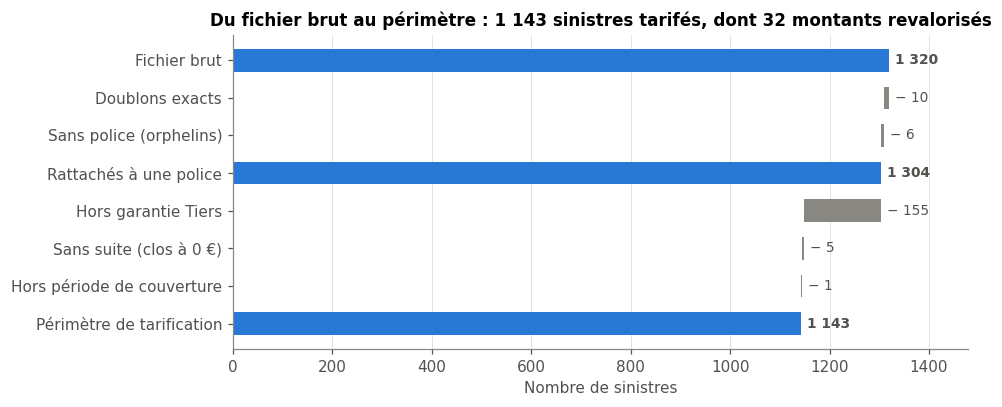

In [37]:
n_brut, n_dedup, n_ratt = len(brut_s), len(brut), len(s)
hg = int((s['hors_garantie'] == 1).sum())
ss = int(((s['sans_suite'] == 1) & (s['hors_garantie'] == 0)).sum())
n_per = int(s['perimetre_tarif'].sum())
etapes = [('Fichier brut', n_brut, True), ('Doublons exacts', n_brut - n_dedup, False),
          ('Sans police (orphelins)', n_dedup - n_ratt, False), ('Rattachés à une police', n_ratt, True),
          ('Hors garantie Tiers', hg, False), ('Sans suite (clos à 0 €)', ss, False),
          ('Hors période de couverture', n_ratt - hg - ss - n_per, False), ('Périmètre de tarification', n_per, True)]

fig, ax = plt.subplots(figsize=(9, 3.8))
niveau = 0
for i, (lab, val, total) in enumerate(etapes):
    if total:
        ax.barh(i, val, color=BLEU, height=0.6)
        niveau = val
        ax.text(val + 12, i, f'{val:,}'.replace(',', ' '), va='center', fontsize=9, color=ENCRE, fontweight='bold')
    else:
        niveau -= val
        ax.barh(i, max(val, 2), left=niveau, color=GRIS, height=0.6)
        ax.text(niveau + val + 12, i, f'− {val}', va='center', fontsize=9, color=ENCRE)
ax.set_yticks(range(len(etapes)), [e[0] for e in etapes]); ax.invert_yaxis()
ax.set_xlim(0, n_brut * 1.12); ax.grid(axis='y', visible=False)
ax.set_xlabel('Nombre de sinistres')
ax.set_title(f"Du fichier brut au périmètre : {n_per:,} sinistres tarifés".replace(',', ' ')
             + f", dont {int(s.loc[s['perimetre_tarif'] == 1, 'montant_impute'].sum())} montants revalorisés")
plt.tight_layout(); plt.show()

---
## B.5 Méthode Peaks Over Threshold (POT)

Au-delà d'un seuil `u` suffisamment élevé, les excès `X − u` suivent approximativement une loi
de Pareto généralisée (théorème de Pickands–Balkema–de Haan) :

$$P(X - u \le y \mid X > u) = 1 - \left(1 + \xi \frac{y}{\sigma(u)}\right)^{-1/\xi}$$

- `ξ` (forme) mesure l'épaisseur de la queue : `ξ > 0` queue de type Pareto, `ξ = 0` exponentielle ;
  l'espérance n'existe que si `ξ < 1`.
- `σ(u)` (échelle) dépend du seuil. Si la GPD est valide à partir de `u₀`, elle l'est au-dessus
  avec `σ(u) = σ(u₀) + ξ (u − u₀)` : pour `ξ ≥ 0`, σ **croît** avec le seuil dans la zone de
  validité. Minimiser σ̂(u) dans cette zone revient donc à retenir le seuil le plus bas où la GPD
  est valide, c'est-à-dire celui qui conserve le plus de graves pour le modèle.

### B.5.1 Mean Excess Plot

`e(u) = E[X − u | X > u]`. Pour une GPD, `e(u) = (σ + ξu) / (1 − ξ)` est **linéaire** en `u` :
on cherche le seuil à partir duquel la courbe devient une droite.

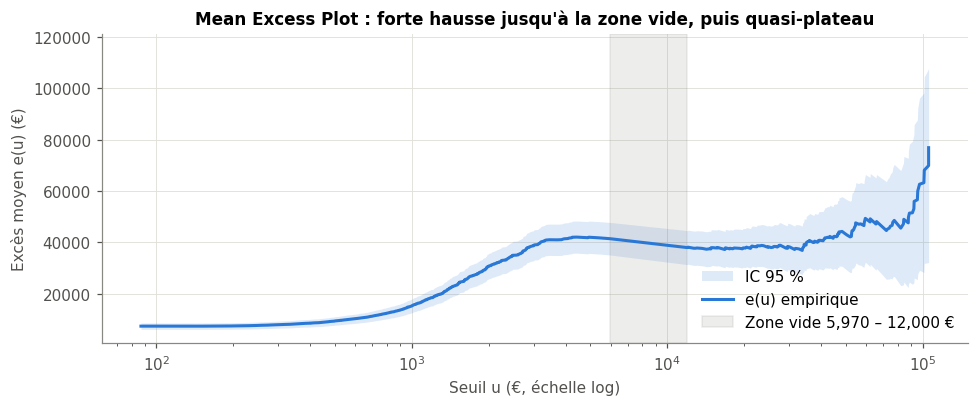

u ≈   1,000 € : e(u) =   15,206 €  (n = 561)
u ≈   3,000 € : e(u) =   38,841 €  (n = 204)
u ≈   6,000 € : e(u) =   37,952 €  (n = 166)
u ≈  12,100 € : e(u) =   37,706 €  (n = 164)
u ≈  20,000 € : e(u) =   37,756 €  (n = 134)
u ≈  40,000 € : e(u) =   40,700 €  (n = 74)


In [38]:
x = np.sort(montants_seuil['montant'].values)             # échantillon du seuil uniquement
u_mep = x[:-10]                                  # on n'interprète pas les 10 derniers points
me   = np.array([(x[x > u] - u).mean() for u in u_mep])
sd   = np.array([(x[x > u] - u).std(ddof=1) for u in u_mep])
n_ex = np.array([(x > u).sum() for u in u_mep])
ic   = 1.96 * sd / np.sqrt(n_ex)

bas, haut = x[x < 10_000].max(), x[x > 10_000].min()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(u_mep, me - ic, me + ic, color=BLEU, alpha=0.15, linewidth=0, label='IC 95 %')
ax.plot(u_mep, me, color=BLEU, lw=2, label='e(u) empirique')
ax.axvspan(bas, haut, color=GRIS, alpha=0.15, label=f'Zone vide {bas:,.0f} – {haut:,.0f} €')
ax.set_xscale('log')
ax.set_xlabel('Seuil u (€, échelle log)'); ax.set_ylabel('Excès moyen e(u) (€)')
ax.set_title('Mean Excess Plot : forte hausse jusqu\'à la zone vide, puis quasi-plateau')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

for u0 in [1_000, 3_000, 6_000, 12_100, 20_000, 40_000]:
    i = np.searchsorted(u_mep, u0)
    print(f'u ≈ {u0:>7,} € : e(u) = {me[i]:>8,.0f} €  (n = {n_ex[i]})')

**Lecture.** En dessous de ~6 000 €, `e(u)` monte très vite : chaque seuil franchi retire des
sinistres attritionnels, et l'excès moyen est tiré par les graves restants. Ce n'est pas le
comportement d'une queue unique. Au-delà de la zone vide, `e(u)` devient presque plat
(pente faible et positive) : c'est la zone de linéarité recherchée, cohérente avec un `ξ` faible
et positif.

### B.5.2 Ajustement de la GPD sur une grille de seuils

Grille de 500 € en 500 €, ajustement par maximum de vraisemblance
(`scipy.stats.genpareto`, localisation fixée à 0 sur les excès). Pour chaque seuil :

- erreurs-types asymptotiques : `se(ξ̂) = (1 + ξ̂)/√n`, `se(σ̂) = σ̂ √(2(1 + ξ̂)/n)` ;
- test d'adéquation de Kolmogorov–Smirnov des excès à la GPD ajustée (p-valeur approchée,
  conservatrice puisque les paramètres sont estimés sur le même échantillon).

In [39]:
def ajuste_gpd(x, u):
    e = x[x > u] - u
    n = len(e)
    xi, _, sigma = stats.genpareto.fit(e, floc=0)
    return {'u': u, 'n': n, 'xi': xi, 'se_xi': (1 + xi) / np.sqrt(n),
            'sigma': sigma, 'se_sigma': sigma * np.sqrt(2 * (1 + xi) / n),
            'ks_p': stats.kstest(e, 'genpareto', args=(xi, 0, sigma)).pvalue,
            'cv_exces': e.std(ddof=1) / e.mean()}

N_GRILLE = 30                                     # en dessous, l'ajustement n'a plus de sens
grille = pd.DataFrame([ajuste_gpd(x, u) for u in np.arange(500, 80_001, 500)
                       if (x > u).sum() >= N_GRILLE])
print('Seuils ajustés :', len(grille), f'(de {grille.u.min():,.0f} à {grille.u.max():,.0f} €)')
apercu_seuils = [1_000, 2_000, 3_000, 4_000, 6_000, 8_000, 10_000, 12_000, 15_000,
                 20_000, 25_000, 30_000, 33_000, 40_000, 50_000]
grille[grille.u.isin(apercu_seuils)].round({'xi': 3, 'se_xi': 3, 'sigma': 0, 'se_sigma': 0,
                                           'ks_p': 3, 'cv_exces': 3})

Seuils ajustés : 152 (de 500 à 76,000 €)


,u,n,xi,se_xi,sigma,se_sigma,ks_p,cv_exces
1,1000,562,2.130,0.132,689.0,73.0,0.000,2.124
3,2000,266,0.512,0.093,17357.0,1851.0,0.000,1.338
5,3000,205,0.078,0.075,35619.0,3653.0,0.070,1.108
7,4000,187,0.026,0.075,40272.0,4218.0,0.003,1.042
11,6000,178,0.025,0.077,40338.0,4330.0,0.002,1.042
15,8000,178,0.063,0.080,36868.0,4030.0,0.044,1.095
19,10000,178,0.113,0.083,33130.0,3705.0,0.559,1.153
23,12000,166,0.108,0.086,33816.0,3907.0,0.819,1.148
29,15000,154,0.124,0.091,33066.0,3995.0,0.768,1.165
39,20000,135,0.148,0.099,32134.0,4190.0,0.711,1.189


### B.5.3 Stabilité de ξ̂(u) et σ̂(u)

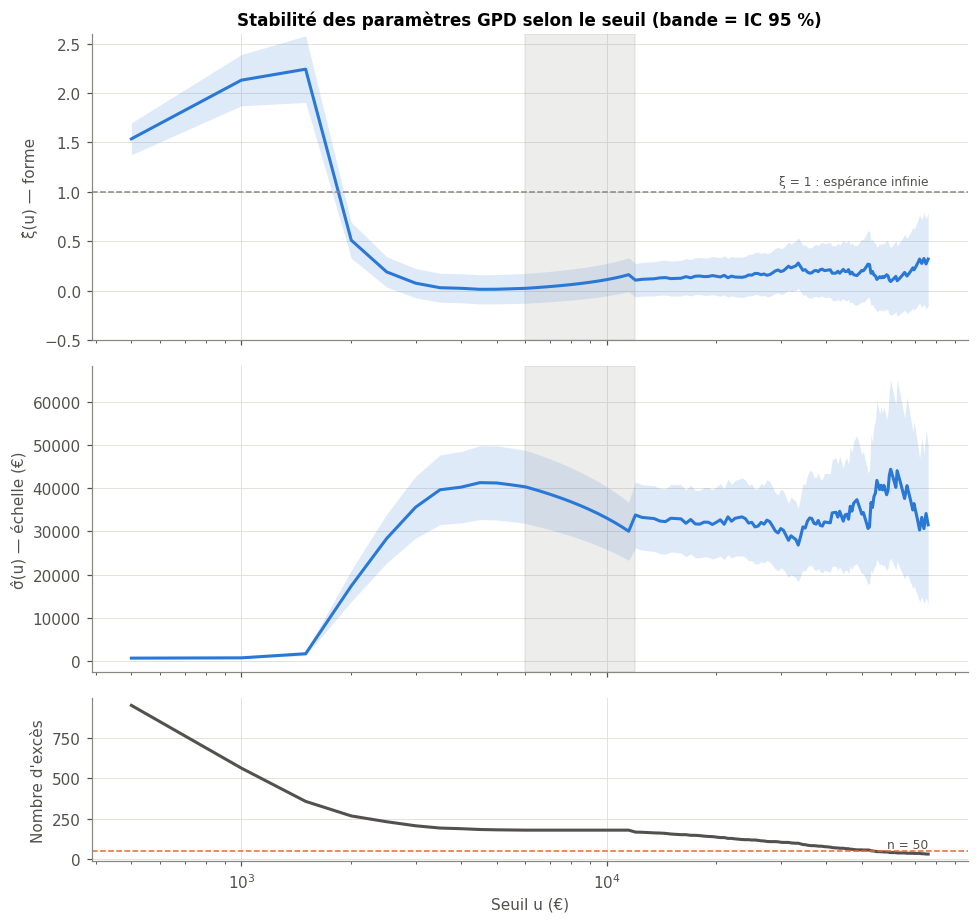

In [40]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True,
                         gridspec_kw={'height_ratios': [3, 3, 1.6]})
g = grille
for ax, col, lab in [(axes[0], 'xi', 'ξ̂(u) — forme'), (axes[1], 'sigma', 'σ̂(u) — échelle (€)')]:
    ax.fill_between(g.u, g[col] - 1.96 * g['se_' + col], g[col] + 1.96 * g['se_' + col],
                    color=BLEU, alpha=0.15, linewidth=0)
    ax.plot(g.u, g[col], color=BLEU, lw=2)
    ax.axvspan(bas, haut, color=GRIS, alpha=0.15)
    ax.set_ylabel(lab)
axes[0].set_ylim(-0.5, 2.6); axes[0].axhline(1, color=GRIS, lw=1, ls='--')
axes[0].text(g.u.max(), 1.04, 'ξ = 1 : espérance infinie', ha='right', va='bottom', color=ENCRE, fontsize=8)
axes[0].set_title('Stabilité des paramètres GPD selon le seuil (bande = IC 95 %)')
axes[2].plot(g.u, g.n, color=ENCRE, lw=2)
axes[2].axhline(50, color=ORANGE, lw=1, ls='--')
axes[2].text(g.u.max(), 52, 'n = 50', ha='right', va='bottom', color=ENCRE, fontsize=8)
axes[2].set_ylabel("Nombre d'excès"); axes[2].set_xlabel('Seuil u (€)')
axes[2].set_xscale('log')
plt.tight_layout(); plt.show()

**Lecture.**
- **u < 2 000 €** : ξ̂ ≈ 1,5 à 2,3 (espérance infinie). La GPD s'ajuste sur le mélange des deux
  populations : elle est inexploitable, et σ̂ y est artificiellement petit (~600 €), car il
  décrit la dispersion des attritionnels.
- **2 000 – 12 000 €** : ξ̂ chute presque à 0 (≈ 0,02 vers 5 000 €), et σ̂ monte jusqu'à ~41 000 €
  puis redescend. C'est la zone de transition : le seuil traverse la fin des attritionnels, puis la zone
  vide, où les excès se décalent sans qu'aucun sinistre ne sorte de l'échantillon.
- **u > 12 000 €** : ξ̂ ≈ 0,11 – 0,25 et σ̂ ≈ 29 000 – 35 000 €, stables à l'intérieur de leurs
  intervalles de confiance. C'est la zone de validité de la GPD.

### B.5.4 Choix du seuil : minimisation de σ̂(u)

Le critère imposé est `u* = argmin σ̂(u)` sous la contrainte d'un nombre suffisant d'excès. On
l'applique en trois temps : d'abord tel quel, pour montrer pourquoi il doit être restreint,
puis sur le domaine où la GPD est valide, et enfin en tenant compte de l'incertitude de σ̂.

In [41]:
N_MIN = 50                                   # prudence : 1 277 montants seulement au total

# Étape a — critère appliqué sur toute la grille
g50 = grille[grille.n >= N_MIN]
pot_brut = g50.loc[g50.sigma.idxmin()]
print(f'a) argmin σ̂ sans restriction : u = {pot_brut.u:,.0f} €, σ̂ = {pot_brut.sigma:,.0f} €, '
      f'ξ̂ = {pot_brut.xi:.2f}, p(KS) = {pot_brut.ks_p:.3f}  →  rejeté (ξ̂ > 1, GPD rejetée)')

# Étape b — domaine de validité : GPD non rejetée (KS à 5 %) à ce seuil ET à tous les seuils
# supérieurs (propriété de stabilité par seuil de la GPD), ξ̂ < 1, et n ≥ N_MIN
g = grille.sort_values('u').reset_index(drop=True)
g['stable'] = (g.ks_p > 0.05)[::-1].cummin()[::-1]
admissible = g[g.stable & (g.xi < 1) & (g.n >= N_MIN)]
u_valide = admissible.u.min()
mini = admissible.loc[admissible.sigma.idxmin()]
print(f'\nb) Domaine admissible : u de {u_valide:,.0f} à {admissible.u.max():,.0f} € '
      f'({len(admissible)} seuils)')
print(f'   argmin σ̂ sur ce domaine : u_min = {mini.u:,.0f} €, σ̂ = {mini.sigma:,.0f} € '
      f'(IC 95 % : {mini.sigma - 1.96 * mini.se_sigma:,.0f} – {mini.sigma + 1.96 * mini.se_sigma:,.0f}), '
      f'n = {mini.n:.0f}')

# Étape c — les σ̂ du domaine sont-ils significativement plus grands que le minimum ?
borne = mini.sigma + 1.96 * mini.se_sigma
indiff = admissible[admissible.sigma <= borne]
u_star = indiff.u.min()
print(f'\nc) Seuils dont σ̂ ne dépasse pas la borne haute de l\'IC du minimum ({borne:,.0f} €) : '
      f'{len(indiff)} sur {len(admissible)}')
print(f'   Le plus bas : u* = {u_star:,.0f} €')

# Même partition pour tout seuil dans la zone vide
sous, dessus = x[x <= u_star].max(), x[x > u_star].min()
print(f'\n   Tout seuil de l\'intervalle [{sous:,.2f} ; {dessus:,.2f}[ € donne exactement '
      f'la même séparation : {int((x > u_star).sum())} montants au-dessus du seuil.')

a) argmin σ̂ sans restriction : u = 500 €, σ̂ = 625 €, ξ̂ = 1.54, p(KS) = 0.000  →  rejeté (ξ̂ > 1, GPD rejetée)

b) Domaine admissible : u de 8,500 à 53,500 € (91 seuils)
   argmin σ̂ sur ce domaine : u_min = 33,500 €, σ̂ = 26,837 € (IC 95 % : 18,287 – 35,388), n = 97

c) Seuils dont σ̂ ne dépasse pas la borne haute de l'IC du minimum (35,388 €) : 83 sur 91
   Le plus bas : u* = 9,000 €

   Tout seuil de l'intervalle [5,970.25 ; 12,000.00[ € donne exactement la même séparation : 178 montants au-dessus du seuil.


**Pourquoi l'étape c ?** Sur le domaine de validité, σ̂(u) fluctue entre ~29 000 et ~35 000 €
avec une erreur-type de 4 000 à 7 000 € : l'argmin ponctuel de l'étape b n'est pas
significativement plus petit que ses voisins. Il dépend du bruit d'échantillonnage, pas d'une propriété de la
queue. En théorie, σ(u) croît avec le seuil dans la zone de validité (§ 5, `ξ > 0`) : le vrai
minimum est à la borne basse de cette zone. On retient donc le **plus petit seuil statistiquement
indiscernable du minimum** : c'est la lecture prudente du critère, et elle conserve le maximum
d'excès pour le modèle des graves.

In [42]:
# Sensibilité : que change le seuil ?
def partition(u):
    fi = montants_seuil['montant']
    gr = fi[fi > u]
    return {'seuil (€)': f'{u:,.0f}', 'graves': len(gr),
            'part des sinistres (%)': round(len(gr) / len(fi) * 100, 1),
            'part de la charge (%)': round(gr.sum() / fi.sum() * 100, 1),
            'coût moyen grave (€)': round(gr.mean(), 0),
            'coût moyen attritionnel (€)': round(fi[fi <= u].mean(), 0)}

sens = pd.DataFrame([partition(u) for u in [3_000, 6_000, u_star, 20_000, mini.u, 50_000]])
sens.index = ['', '', 'u* retenu', '', 'u_min (étape b)', '']
sens

,seuil (€),graves,part des sinistres (%),part de la charge (%),coût moyen grave (€),coût moyen attritionnel (€)
,"3,000",205,16.1,90.0,41652.0,886.0
,"6,000",178,13.9,88.9,47393.0,957.0
u* retenu,"9,000",178,13.9,88.9,47393.0,957.0
,"20,000",135,10.6,82.1,57713.0,1486.0
u_min (étape b),"33,500",97,7.6,71.8,70268.0,2264.0
,"50,000",56,4.4,54.7,92627.0,3522.0


### B.5.5 Qualité de l'ajustement GPD au seuil retenu

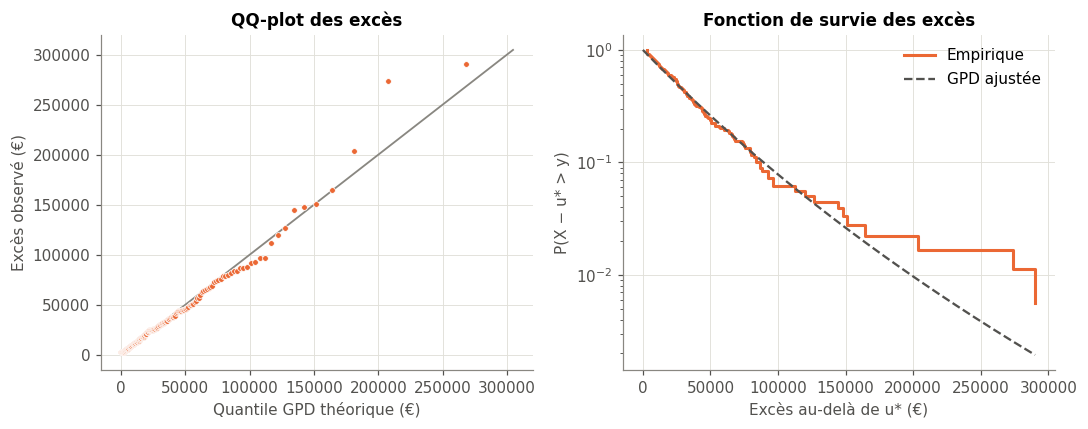

u* = 9,000 € | n = 178 | ξ̂ = 0.086 (IC 95 % : -0.073 ; 0.246) | σ̂ = 35,040 € | p(KS) = 0.175


In [43]:
fit = g.loc[g.u == u_star].iloc[0]
e = np.sort(x[x > u_star] - u_star)
n = len(e)
p = (np.arange(1, n + 1) - 0.5) / n
q_th = stats.genpareto.ppf(p, fit.xi, 0, fit.sigma)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(q_th, e, s=14, color=ORANGE, edgecolor='white', linewidth=0.5, zorder=3)
lim = max(q_th.max(), e.max()) * 1.05
axes[0].plot([0, lim], [0, lim], color=GRIS, lw=1.2)
axes[0].set_xlabel('Quantile GPD théorique (€)'); axes[0].set_ylabel('Excès observé (€)')
axes[0].set_title('QQ-plot des excès')

grid_y = np.linspace(0, e.max(), 300)
axes[1].step(e, 1 - np.arange(1, n + 1) / (n + 1), where='post', color=ORANGE, lw=2, label='Empirique')
axes[1].plot(grid_y, stats.genpareto.sf(grid_y, fit.xi, 0, fit.sigma), color=ENCRE, lw=1.5,
             ls='--', label='GPD ajustée')
axes[1].set_yscale('log'); axes[1].set_xlabel('Excès au-delà de u* (€)')
axes[1].set_ylabel('P(X − u* > y)'); axes[1].set_title('Fonction de survie des excès')
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print(f'u* = {u_star:,.0f} € | n = {n} | ξ̂ = {fit.xi:.3f} (IC 95 % : {fit.xi - 1.96 * fit.se_xi:.3f} ; '
      f'{fit.xi + 1.96 * fit.se_xi:.3f}) | σ̂ = {fit.sigma:,.0f} € | p(KS) = {fit.ks_p:.3f}')

---
## B.6 Croisement du seuil avec la nature des sinistres

Argument de robustesse : un seuil purement statistique doit retrouver la frontière métier
entre sinistres légers et graves. On compte les discordances dans les deux sens.

In [44]:
ms = montants_seuil.copy()
ms['au_dessus_u*'] = (ms['montant'] > u_star).map({True: 'au-dessus', False: 'en dessous'})
print(pd.crosstab(ms['nature_sinistre'], ms['au_dessus_u*'], margins=True).to_string())

leg_haut = (~ms['nature_sinistre'].isin(natures_graves + ['Inconnu'])) & (ms['montant'] > u_star)
grv_bas  = ms['nature_sinistre'].isin(natures_graves) & (ms['montant'] <= u_star)
print('\nNature légère au-dessus de u* :', int(leg_haut.sum()))
print('Nature grave en dessous de u*  :', int(grv_bas.sum()))

au_dessus_u*           au-dessus  en dessous   All
nature_sinistre                                   
Bris De Glace                  0         334   334
Catastrophe Naturelle         15           0    15
Collision Majeure             51           0    51
Collision Mineure              0         224   224
Corporel Grave                61           0    61
Dégât Matériel Léger           0         308   308
Incendie Total                24           0    24
Inconnu                        2           8    10
Vandalisme                     0          58    58
Vol Partiel                    0         167   167
Vol Total                     25           0    25
All                          178        1099  1277

Nature légère au-dessus de u* : 0
Nature grave en dessous de u*  : 0


**Lecture.** Le seuil statistique et la nature du sinistre donnent la même partition pour toutes
les natures connues. Seule la modalité `Inconnu` se répartit des deux côtés : c'est justement le
cas où le montant apporte l'information que la nature ne donne pas. Cette concordance est
l'argument de robustesse du seuil.

---
## B.7 Comparaison de quatre méthodes de séparation

Le POT n'est pas la seule façon de séparer les graves. On le confronte à trois autres méthodes, de
natures différentes, jugées sur les mêmes critères :

| # | Méthode | Principe |
| --- | --- | --- |
| 1 | **POT** — argmin σ̂ sur le domaine de validité de la GPD, avec règle d'indifférence (§ 5.4) | théorie des valeurs extrêmes : seuil au-delà duquel les excès suivent une GPD |
| 2 | **Quantiles empiriques** 90 % et 95 % | pratique de marché : une proportion fixe de sinistres est déclarée grave, sans hypothèse de loi |
| 3 | **Plus grand écart** entre montants consécutifs (échelle log) | rupture naturelle de la distribution |
| 4 | **Mélange de deux lois log-normales** (algorithme EM) | modèle à deux populations : seuil où la probabilité a posteriori d'être grave vaut 50 % |

**Critères de comparaison :**
- **effectif de graves** : il en faut au moins 50 pour un modèle dédié ;
- **part de charge** des graves ;
- **adéquation GPD** au-delà du seuil : ξ̂ et p-valeur KS ;
- **homogénéité des attritionnels** : CV des montants, car un GLM Gamma suppose un CV constant ;
- **discordances avec la nature** du sinistre (contrôle métier de la section 6) ;
- **stabilité** : largeur de l'intervalle de seuils qui donne exactement la même partition.

### B.7.1 Calcul des seuils candidats

In [45]:
n_fi = len(x)

# Méthode 2 : quantiles empiriques
q90, q95 = np.quantile(x, [0.90, 0.95])

# Méthode 3 : plus grand écart en log, seuil au milieu géométrique de l'écart
i_gap = np.argmax(np.diff(np.log(x)))
u_gap = np.sqrt(x[i_gap] * x[i_gap + 1])

# Méthode 4 : mélange de deux log-normales, estimé par EM
lx = np.log(x)
w, mu, sd = np.array([0.8, 0.2]), np.quantile(lx, [0.4, 0.95]), np.array([1.0, 1.0])
for _ in range(1000):
    dens = w * stats.norm.pdf(lx[:, None], mu, sd)
    r = dens / dens.sum(axis=1, keepdims=True)
    w_new = r.mean(axis=0)
    mu = (r * lx[:, None]).sum(axis=0) / r.sum(axis=0)
    sd = np.sqrt((r * (lx[:, None] - mu) ** 2).sum(axis=0) / r.sum(axis=0))
    if np.abs(w_new - w).max() < 1e-10:
        break
    w = w_new
t = np.linspace(mu[0], mu[1], 20_000)
post = w[1] * stats.norm.pdf(t, mu[1], sd[1])
post = post / (post + w[0] * stats.norm.pdf(t, mu[0], sd[0]))
u_mel = float(np.exp(t[np.argmin(np.abs(post - 0.5))]))
print(f'Mélange EM : poids graves = {w[1]:.3f}, médianes = {np.exp(mu[0]):,.0f} € / {np.exp(mu[1]):,.0f} €, '
      f'écarts-types log = {sd[0]:.2f} / {sd[1]:.2f}')

candidats = {
    '1. POT (u*)'                 : u_star,
    '2a. Quantile 90 %'           : q90,
    '2b. Quantile 95 %'           : q95,
    '3. Plus grand écart (log)'   : u_gap,
    '4. Mélange log-normal (EM)'  : u_mel,
}
for nom, u in candidats.items():
    print(f'  {nom:<30} u = {u:>10,.0f} €')

Mélange EM : poids graves = 0.140, médianes = 743 € / 35,330 €, écarts-types log = 0.71 / 0.74
  1. POT (u*)                    u =      9,000 €
  2a. Quantile 90 %              u =     21,458 €
  2b. Quantile 95 %              u =     44,829 €
  3. Plus grand écart (log)      u =      8,464 €
  4. Mélange log-normal (EM)     u =      6,380 €


### B.7.2 Tableau comparatif

In [46]:
ms = montants_seuil
nat_grave   = ms['nature_sinistre'].isin(natures_graves)
nat_legere  = ~ms['nature_sinistre'].isin(natures_graves + ['Inconnu'])

def evalue(nom, est_grave, u=None):
    mt = ms['montant']
    attr, gr = mt[~est_grave], mt[est_grave]
    ligne = {'méthode': nom,
             'seuil (€)': np.nan if u is None else round(u),
             'graves': int(est_grave.sum()),
             'part charge graves (%)': round(gr.sum() / mt.sum() * 100, 1),
             'CV attritionnels': round(attr.std() / attr.mean(), 2),
             'discordances nature': int((nat_legere & est_grave).sum() + (nat_grave & ~est_grave).sum())}
    if u is not None:
        exc = x[x > u] - u
        xi, _, sig = stats.genpareto.fit(exc, floc=0)
        ligne['ξ̂'] = round(xi, 3)
        ligne['p KS'] = round(stats.kstest(exc, 'genpareto', args=(xi, 0, sig)).pvalue, 3)
        ligne['même partition entre (€)'] = f'{x[x <= u].max():,.0f} et {x[x > u].min():,.0f}'
    return ligne

comparaison = pd.DataFrame([evalue(nom, ms['montant'] > u, u) for nom, u in candidats.items()]).set_index('méthode')
comparaison['≥ 50 graves'] = np.where(comparaison['graves'] >= N_MIN, 'oui', 'non')
comparaison

,seuil (€),graves,part charge graves (%),CV attritionnels,discordances nature,ξ̂,p KS,même partition entre (€),≥ 50 graves
méthode,,,,,,,,,
1. POT (u*),9000,178,88.9,0.78,0,0.086,0.175,"5,970 et 12,000",oui
2a. Quantile 90 %,21458,128,80.6,1.99,49,0.140,0.648,"21,448 et 21,472",oui
2b. Quantile 95 %,44829,64,58.6,2.39,113,0.190,0.964,"44,738 et 45,195",oui
3. Plus grand écart (log),8464,178,88.9,0.78,0,0.074,0.085,"5,970 et 12,000",oui
4. Mélange log-normal (EM),6380,178,88.9,0.78,0,0.032,0.004,"5,970 et 12,000",oui


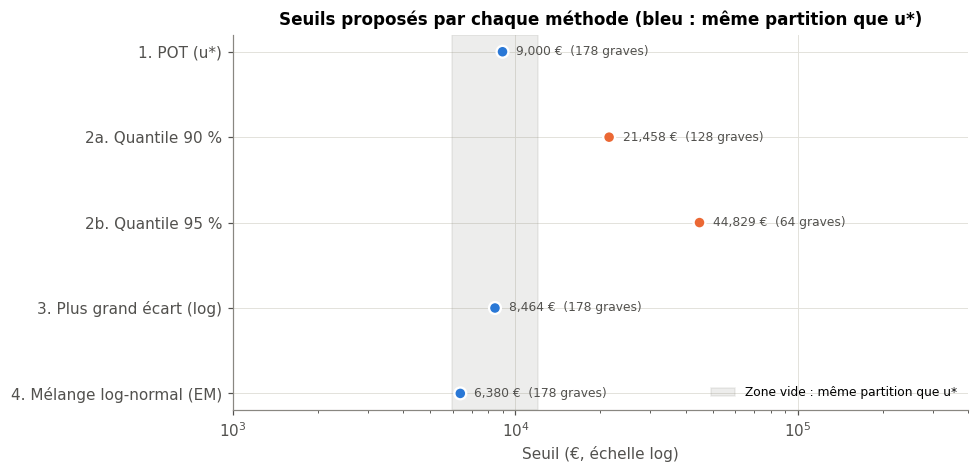

In [47]:
fig, ax = plt.subplots(figsize=(9, 4.4))
noms = list(candidats)[::-1]
vals = [candidats[k] for k in noms]
meme_partition = [(x > v).sum() == (x > u_star).sum() for v in vals]
ax.axvspan(x[x <= u_star].max(), x[x > u_star].min(), color=GRIS, alpha=0.15,
           label='Zone vide : même partition que u*')
ax.scatter(vals, range(len(noms)), s=60, zorder=3, edgecolor='white', linewidth=1.5,
           color=[BLEU if m else ORANGE for m in meme_partition])
for i, v in enumerate(vals):
    ax.text(v * 1.12, i, f'{v:,.0f} €  ({int((x > v).sum())} graves)', va='center', fontsize=8, color=ENCRE)
ax.set_yticks(range(len(noms)), noms)
ax.set_xscale('log'); ax.set_xlim(1_000, 400_000)
ax.set_xlabel('Seuil (€, échelle log)')
ax.set_title('Seuils proposés par chaque méthode (bleu : même partition que u*)')
ax.legend(frameon=False, loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

**Lecture de la comparaison.**

- **Trois méthodes sur quatre convergent vers la même partition** : POT (1), plus grand écart (3) et
  mélange log-normal (4). Elles reposent sur des principes indépendants (queue de distribution,
  rupture de la distribution, modèle à deux populations) et aboutissent toutes à 178 graves dans
  l'échantillon du seuil, 88,9 % de la charge, **aucune discordance** avec la nature et le CV
  attritionnel le plus faible (0,78). Leurs seuils diffèrent (6 400 à 9 000 €) mais tombent tous dans
  la zone vide ]5 970 ; 12 000[ € : la partition ne change pas quand le seuil varie du simple au double.
- **Les quantiles** (2a, 2b) placent le seuil à l'intérieur de la population des graves : 49 à 113
  sinistres de nature grave deviennent attritionnels, et le CV attritionnel passe de 0,78 à 2,0 – 2,4.
  Le GLM Gamma attritionnel mélangerait alors des sinistres à 1 000 € et à 30 000 €, ce qui contredit
  l'hypothèse de CV constant. Leur partition bouge aussi dès que le seuil se déplace de quelques
  dizaines d'euros.
- **Pourquoi retenir le POT plutôt qu'un autre point de la zone vide ?** La partition est la même ;
  seul change le point d'origine des excès, donc le paramétrage de la GPD des graves. Le mélange
  log-normal place le seuil au bas de la zone vide : les excès commencent alors par un intervalle
  vide de 5 600 € que la GPD, dont la densité est maximale en 0, décrit mal (p KS = 0,004). À
  u* = 9 000 €, l'ajustement est acceptable (p = 0,18) et le critère imposé (σ̂ minimal) est respecté.

---
## B.8 Variable `sinistre_grave`

- Le classement se fait sur le **montant retenu** : montant observé, ou montant revalorisé par le coût
  moyen de la nature (sinistres à montant manquant, codé ou forfaitaire). `sinistre_grave = 1` si ce
  montant dépasse `u*`.
- Sinistre **sans suite** (dossier clos à 0 €) : `sinistre_grave = 0`, hors périmètre.
- Un montant revalorisé vaut le coût moyen de sa nature : il est donc classé comme sa nature, règle
  dont la section 6 a montré qu'elle coïncide exactement avec le seuil (vérifié ci-dessous).

In [48]:
s['sinistre_grave'] = ((s['montant_retenu'] > u_star) & (s['sans_suite'] == 0)).astype(int)
s['source_classement'] = np.select([s['sans_suite'] == 1, s['montant_impute'] == 1],
                                   ['sans suite', 'montant revalorisé'], 'montant observé')
rev = s['montant_impute'] == 1
print(pd.crosstab(s['source_classement'], s['sinistre_grave'].map({0: 'attritionnel', 1: 'grave'}), margins=True).to_string())
print('\nRevalorisés classés autrement que leur nature :',
      int((rev & (s['sinistre_grave'] != s['nature_sinistre'].isin(natures_graves).astype(int))).sum()))

p = s[s['perimetre_tarif'] == 1]
resume_B = p.groupby('sinistre_grave').agg(
    sinistres        = ('id_sinistre', 'count'),
    dont_revalorises = ('montant_impute', 'sum'),
    charge           = ('montant_retenu', 'sum'),
    cout_moyen       = ('montant_retenu', 'mean'),
    cout_median      = ('montant_retenu', 'median'),
    pct_ouverts      = ('statut', lambda v: (v == 'Ouvert').mean() * 100))
resume_B.index = resume_B.index.map({0: 'Attritionnels', 1: 'Graves'})
resume_B['part_sinistres_%'] = resume_B['sinistres'] / resume_B['sinistres'].sum() * 100
resume_B['part_charge_%']    = resume_B['charge'] / resume_B['charge'].sum() * 100
resume_B.loc['Total'] = [len(p), p['montant_impute'].sum(), p['montant_retenu'].sum(), p['montant_retenu'].mean(),
                         p['montant_retenu'].median(), (p['statut'] == 'Ouvert').mean() * 100, 100, 100]
resume_B.round(1)

sinistre_grave      attritionnel  grave   All
source_classement                            
montant observé             1099    166  1265
montant revalorisé            18     16    34
sans suite                     5      0     5
All                         1122    182  1304

Revalorisés classés autrement que leur nature : 0


,sinistres,dont_revalorises,charge,cout_moyen,cout_median,pct_ouverts,part_sinistres_%,part_charge_%
sinistre_grave,,,,,,,,
Attritionnels,974.0,16.0,931747.1,956.6,770.9,14.6,85.2,9.9
Graves,169.0,16.0,8492646.0,50252.3,39044.5,48.5,14.8,90.1
Total,1143.0,32.0,9424393.1,8245.3,911.5,19.6,100.0,100.0


**Pont entre l'échantillon du seuil et le périmètre de tarification.** Les graves de la section 7 sont
comptés sur `montants_seuil` (montants observés, y compris hors garantie) ; ceux du périmètre sur les
sinistres tarifés, y compris ceux dont le montant a été revalorisé.

In [49]:
G, dans, ech = s['sinistre_grave'] == 1, s['perimetre_tarif'] == 1, montants_seuil
obs_pos = s['montant_sinistre'] > 0
pont = pd.Series({
    'Graves de montants_seuil (montant observé > u*)'    : int((ech['montant'] > u_star).sum()),
    '− sinistres absents de la base de la partie A'      : -int(((ech['montant'] > u_star) & ~ech['dans_fichier_A']).sum()),
    '− hors garantie'                                    : -int((G & obs_pos & (s['hors_garantie'] == 1)).sum()),
    '− hors périmètre, autre motif'                      : -int((G & obs_pos & ~dans & (s['hors_garantie'] == 0)).sum()),
    '= graves à montant observé du périmètre'            : int((G & obs_pos & dans).sum()),
    '+ montants manquants revalorisés (nature grave)'    : int((G & dans & ~obs_pos).sum()),
    '= graves du périmètre de tarification'              : int((G & dans).sum()),
})
print(pont.to_string())
assert pont.iloc[:4].sum() == pont.iloc[4] and pont.iloc[4] + pont.iloc[5] == pont.iloc[6]

Graves de montants_seuil (montant observé > u*)    178
− sinistres absents de la base de la partie A        0
− hors garantie                                    -13
− hors périmètre, autre motif                        0
= graves à montant observé du périmètre            165
+ montants manquants revalorisés (nature grave)      4
= graves du périmètre de tarification              169


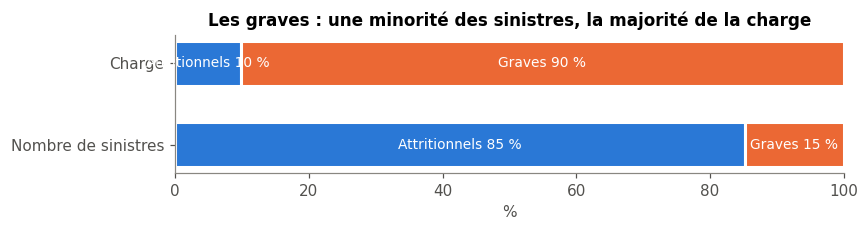

In [50]:
fig, ax = plt.subplots(figsize=(8, 2.2))
parts = resume_B.loc[['Attritionnels', 'Graves'], ['part_sinistres_%', 'part_charge_%']]
for i, (col, lab) in enumerate([('part_sinistres_%', 'Nombre de sinistres'),
                                ('part_charge_%', 'Charge')]):
    a, gr = parts.loc['Attritionnels', col], parts.loc['Graves', col]
    ax.barh(i, a, color=BLEU, height=0.55, edgecolor='white', linewidth=2)
    ax.barh(i, gr, left=a, color=ORANGE, height=0.55, edgecolor='white', linewidth=2)
    ax.text(a / 2, i, f'Attritionnels {a:.0f} %', ha='center', va='center', color='white', fontsize=9)
    ax.text(a + gr / 2, i, f'Graves {gr:.0f} %', ha='center', va='center', color='white', fontsize=9)
ax.set_yticks([0, 1], ['Nombre de sinistres', 'Charge'])
ax.set_xlim(0, 100); ax.set_xlabel('%'); ax.grid(False)
ax.set_title('Les graves : une minorité des sinistres, la majorité de la charge')
plt.tight_layout(); plt.show()

---
## B.9 Agrégation par police

Même logique que la partie A (§ 9.4) : une ligne par police, **zéros compris**, jointure à
gauche. Les colonnes `nb_sinistres`, `nb_sinistres_cout`, `charge_totale` et `nb_sin_{année}`
sont **recalculées sur le périmètre de tarification** (hors garantie et sans suite exclus, montants
revalorisés). Colonnes ajoutées pour les parties C à F :

| Colonne | Contenu |
| --- | --- |
| `nb_attr`, `nb_grave` | nombre de sinistres (cibles des GLM fréquence) |
| `nb_attr_cout`, `nb_grave_cout` | nombre de sinistres valorisés (poids des GLM coût) |
| `charge_attr`, `charge_grave` | charge des sinistres valorisés |
| `…_2023`, `…_2024` | les mêmes, par année de survenance (séparation Train / Test) |

In [51]:
p = s[s['perimetre_tarif'] == 1].copy()
p['annee'] = p['date_sinistre'].dt.year
p['groupe'] = p['sinistre_grave'].map({0: 'attr', 1: 'grave'})

def agrege(df, suffixe=''):
    t = df.groupby(['id_police', 'groupe']).agg(nb=('id_sinistre', 'count'),
                                                 nb_cout=('montant_retenu', 'count'),
                                                 charge=('montant_retenu', 'sum')).unstack('groupe')
    noms = {'nb': 'nb_{g}', 'nb_cout': 'nb_{g}_cout', 'charge': 'charge_{g}'}
    t.columns = [noms[m].format(g=g) + suffixe for m, g in t.columns]
    return t

tables = [agrege(p)] + [agrege(p[p['annee'] == an], f'_{an}') for an in [2023, 2024]]
base_B = base.drop(columns=['nb_sinistres', 'nb_sinistres_cout', 'charge_totale',
                            'nb_sin_2023', 'nb_sin_2024'])
for t in tables:
    base_B = base_B.merge(t, left_on='id_police', right_index=True, how='left')

cols_nb = [c for c in base_B.columns if c.startswith('nb_')]
cols_ch = [c for c in base_B.columns if c.startswith('charge_')]
base_B[cols_nb] = base_B[cols_nb].fillna(0).astype(int)
base_B[cols_ch] = base_B[cols_ch].fillna(0.0)

base_B['nb_sinistres']      = base_B['nb_attr'] + base_B['nb_grave']
base_B['nb_sinistres_cout'] = base_B['nb_attr_cout'] + base_B['nb_grave_cout']
base_B['charge_totale']     = base_B['charge_attr'] + base_B['charge_grave']
for an in [2023, 2024]:
    base_B[f'nb_sin_{an}'] = base_B[f'nb_attr_{an}'] + base_B[f'nb_grave_{an}']

print('Base B :', base_B.shape)
print('Colonnes ajoutées :', sorted(set(base_B.columns) - set(base.columns)))

Base B : (21500, 48)
Colonnes ajoutées : ['charge_attr', 'charge_attr_2023', 'charge_attr_2024', 'charge_grave', 'charge_grave_2023', 'charge_grave_2024', 'nb_attr', 'nb_attr_2023', 'nb_attr_2024', 'nb_attr_cout', 'nb_attr_cout_2023', 'nb_attr_cout_2024', 'nb_grave', 'nb_grave_2023', 'nb_grave_2024', 'nb_grave_cout', 'nb_grave_cout_2023', 'nb_grave_cout_2024']


---
## B.10 Vérification et export

In [52]:
pb = s[s['perimetre_tarif'] == 1]
obs_fi = s[s['montant_fiable'].notna()]
ecart_charge = (base_B['charge_attr'] + base_B['charge_grave'] - base_B['charge_totale']).abs()
controles = {
    'montant nul ou manquant dans montants_seuil': int((montants_seuil['montant'].isna() |
                                                    (montants_seuil['montant'] <= 0)).sum()),
    'orphelin dans montants_seuil'             : int((~montants_seuil['id_police'].astype(str).str.strip()
                                                     .isin(ids_origine)).sum()),
    'montant positif absent de montants_seuil' : int((~s.loc[s['montant_sinistre'] > 0, 'id_sinistre']
                                                     .isin(montants_seuil['id_sinistre'])).sum()),
    'montant inconnu dans le périmètre'        : int(pb['montant_retenu'].isna().sum()),
    'valeur à 12 000 € non revalorisée'        : int(((s['montant_forfait'] == 1) & (s['montant_retenu'] == 12000)).sum()),
    'sans suite dans le périmètre'             : int(pb['sans_suite'].sum()),
    'sans suite classé grave'                  : int(((s['sans_suite'] == 1) & (s['sinistre_grave'] == 1)).sum()),
    'revalorisé classé autrement que sa nature': int(((s['montant_impute'] == 1) & (s['sinistre_grave'] !=
                                                     s['nature_sinistre'].isin(natures_graves).astype(int))).sum()),
    'anomalie_gestion hors clos nul/manquant'  : int((s['anomalie_gestion'] != ((s['statut'] == 'Clos') &
                                                     (s['montant_sinistre'].isna() | (s['montant_sinistre'] == 0)))).sum()),
    'nature légère observée au-dessus de u*'   : int(((~obs_fi['nature_sinistre'].isin(natures_graves + ['Inconnu']))
                                                     & (obs_fi['sinistre_grave'] == 1)).sum()),
    'nature grave observée en dessous de u*'   : int((obs_fi['nature_sinistre'].isin(natures_graves)
                                                     & (obs_fi['sinistre_grave'] == 0)).sum()),
    'grave sous u* (montant retenu)'           : int(((pb['sinistre_grave'] == 1) & (pb['montant_retenu'] <= u_star)).sum()),
    'attritionnel au-dessus de u*'             : int(((pb['sinistre_grave'] == 0) & (pb['montant_retenu'] > u_star)).sum()),
    'hors garantie dans le périmètre'          : int(((s['hors_garantie'] == 1) & (s['perimetre_tarif'] == 1)).sum()),
    'lignes différentes de la base A'          : int(len(base_B) != len(base)),
    'id_police dupliqué'                       : int(base_B['id_police'].duplicated().sum()),
    'total sinistres ≠ périmètre'              : int(base_B['nb_sinistres'].sum() != len(pb)),
    'total graves ≠ périmètre'                 : int(base_B['nb_grave'].sum() != pb['sinistre_grave'].sum()),
    'charge ≠ somme des montants retenus'      : int(abs(base_B['charge_totale'].sum() - pb['montant_retenu'].sum()) > 0.01),
    'attr + grave ≠ total (charge)'            : int((ecart_charge > 0.01).sum()),
    'découpage annuel incohérent'              : int((base_B['nb_sin_2023'] + base_B['nb_sin_2024'] != base_B['nb_sinistres']).sum()),
    'graves < 50 (échantillon)'                : int(base_B['nb_grave'].sum() < 50),
}
for nom, n in controles.items():
    print(f'  {"OK   " if n == 0 else "RESTE"}  {nom:<42} {int(n):>5}')

s.to_csv('sinistres_B.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
base_B.to_csv('base_B.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')

print(f'\nSeuil retenu u* = {u_star:,.0f} €')
print(f'Périmètre : {len(pb):,} sinistres ({int(pb.sinistre_grave.sum())} graves, '
      f'{int(pb.montant_impute.sum())} montants revalorisés) sur {base_B.duree_exposition.sum():,.1f} années-police')
print(f'  2023 : {int(base_B.nb_sin_2023.sum())} sinistres dont {int(base_B.nb_grave_2023.sum())} graves'
      f'  |  2024 : {int(base_B.nb_sin_2024.sum())} dont {int(base_B.nb_grave_2024.sum())} graves')
print(f'Charge : {base_B.charge_totale.sum():,.0f} € dont graves {base_B.charge_grave.sum():,.0f} €')
print('\nFichiers écrits : sinistres_B.csv, base_B.csv')

  OK     montant nul ou manquant dans montants_seuil     0
  OK     orphelin dans montants_seuil                   0
  OK     montant positif absent de montants_seuil       0
  OK     montant inconnu dans le périmètre              0
  OK     valeur à 12 000 € non revalorisée              0
  OK     sans suite dans le périmètre                   0
  OK     sans suite classé grave                        0
  OK     revalorisé classé autrement que sa nature      0
  OK     anomalie_gestion hors clos nul/manquant        0
  OK     nature légère observée au-dessus de u*         0
  OK     nature grave observée en dessous de u*         0
  OK     grave sous u* (montant retenu)                 0
  OK     attritionnel au-dessus de u*                   0
  OK     hors garantie dans le périmètre                0
  OK     lignes différentes de la base A                0
  OK     id_police dupliqué                             0
  OK     total sinistres ≠ périmètre                    0
  OK     tota


Seuil retenu u* = 9,000 €
Périmètre : 1,143 sinistres (169 graves, 32 montants revalorisés) sur 12,359.2 années-police
  2023 : 753 sinistres dont 111 graves  |  2024 : 390 dont 58 graves
Charge : 9,424,393 € dont graves 8,492,646 €

Fichiers écrits : sinistres_B.csv, base_B.csv


### Table de contrôle pour la synthèse

Sinistres non orphelins par statut, type de montant et `anomalie_gestion`. Une dernière ligne
recense les éventuels sinistres de polices absentes de la base (aucune police n'est plus
supprimée en partie A, hors doublons exacts).

In [53]:
type_montant = np.select([s['montant_sinistre'] > 0, s['montant_sinistre'] == 0], ['positif', 'nul'], 'manquant')
table_controle = pd.crosstab([s['statut'], s['anomalie_gestion']], type_montant, margins=True, margins_name='Total')
table_controle.index = table_controle.index.set_names(['statut', 'anomalie_gestion'])
supp = brut[non_orphelin & ~brut['id_sinistre'].isin(s['id_sinistre'])]
table_controle.loc[('Polices supprimées en A', ''), :] = [0, 0, len(supp), len(supp)] if (supp['montant'] > 0).all() else np.nan
table_controle = table_controle.astype(int)
print(table_controle.to_string())
print(f'\nTotal non orphelins : {len(s) + len(supp)} (fichier brut dédoublonné : {int(non_orphelin.sum())})')
print(f"Classés par la nature : {int(s['montant_sinistre'].isna().sum())} sinistres "
      f"({s['montant_sinistre'].isna().sum() / non_orphelin.sum() * 100:.1f} % des {int(non_orphelin.sum())} non orphelins)")

col_0                                     manquant  nul  positif  Total
statut                  anomalie_gestion                               
Clos                    0                        0    0     1031   1031
                        1                       18    5        0     23
Ouvert                  0                        3    1      246    250
Total                                           21    6     1277   1304
Polices supprimées en A                          0    0        0      0

Total non orphelins : 1304 (fichier brut dédoublonné : 1304)
Classés par la nature : 21 sinistres (1.6 % des 1304 non orphelins)


---
## B.11 Justification du seuil retenu

**Seuil retenu : u* = 9 000 €.** Est grave tout sinistre dont le montant retenu (observé, ou
revalorisé par le coût moyen de sa nature) dépasse 9 000 €.

1. **Critère imposé (POT, minimisation de σ̂).** Appliqué sans restriction, il choisit le seuil
   le plus bas de la grille (500 €), où la GPD décrit le mélange des deux populations
   (ξ̂ = 1,5, espérance infinie, rejet KS). On le restreint donc au domaine où la GPD est valide,
   c'est-à-dire non rejetée à ce seuil et à tous les seuils supérieurs, avec au moins 50 excès :
   de 8 500 à 53 500 €. Sur ce domaine, σ̂ est stable autour de 27 000 – 36 000 € et l'argmin
   ponctuel (33 500 €) n'est pas significativement inférieur à ses voisins. u* est le plus petit
   seuil dont σ̂ reste dans l'IC 95 % du minimum. Cette lecture est cohérente avec la théorie :
   pour ξ > 0, σ(u) croît avec u dans la zone de validité, donc son minimum est à la borne basse.
2. **Adéquation.** Au-delà de u* : 178 excès, ξ̂ = 0,09 (IC 95 % : −0,07 ; 0,25), soit une queue
   proche de l'exponentielle, légèrement épaisse ; σ̂ = 35 000 € ; p(KS) = 0,18. Le QQ-plot
   est aligné.
3. **Robustesse.** Deux méthodes indépendantes du POT (plus grand écart, mélange log-normal)
   donnent exactement la même partition ; les quantiles coupent la population des graves en deux.
   La partition est invariante sur tout l'intervalle ]5 970 ; 12 000[ € et concorde à 100 % avec
   la nature pour les natures connues.
4. **Résultat sur le périmètre de tarification** : 169 graves sur 1 143 sinistres, soit
   **14,8 % des sinistres et 90,1 % de la charge**. Coût moyen de 50 250 € contre 957 € pour les
   attritionnels.

**Limites à reporter dans la synthèse.**
- 48 % des graves du périmètre sont des dossiers ouverts. À nature égale, leurs montants ne sont
  pas plus faibles que ceux des dossiers clos (§ 2.3), mais sans triangle de développement on ne
  peut pas exclure une dérive de la charge ultime.
- 12 montants identiques à 12 000,00 €, d'origine inexpliquée et sans lien avec le statut : ils
  sont revalorisés par le coût moyen de leur nature.
- Pont entre les deux décomptes : 178 graves de l'échantillon POT − 13 hors garantie + 4 montants
  manquants revalorisés (nature grave) = 169 graves du périmètre (section 8).
- 2024 ne compte que 58 graves : la validation temporelle des graves reste peu précise.

### Ce que les parties C à F reprennent
- La tarification repose sur **`base_B`** : `nb_sinistres`, `nb_sinistres_cout` et `charge_totale`
  y sont recalculés sur le périmètre de tarification (hors garantie et sans suite exclus, montants
  revalorisés).
- Cibles : `nb_attr` / `nb_grave` (fréquence, offset `log_exposition`) ; `charge_attr / nb_attr_cout`
  et `charge_grave / nb_grave_cout` (coût moyen, poids = nombre de sinistres valorisés).
- Colonnes `…_2023` / `…_2024` pour le contrôle temporel de la partie F.

---
# Partie C — Approche fréquence × coût

Toute la tarification repose sur **`base_B`** : une ligne par police, sinistres restreints au
**périmètre de tarification** (hors garantie et sans suite exclus), montants revalorisés, séparation
attritionnels / graves.

Prime pure = Fréquence × Coût moyen, calculée globalement puis **variable par variable** : cette
analyse univariée montre quelles variables portent réellement du risque, avant les GLM.

In [54]:
base = base_B.copy()
expo_tot = base['duree_exposition'].sum()
print('Base de tarification :', base.shape, f'| exposition : {expo_tot:,.1f} années-police',
      f"| sinistres : {int(base['nb_sinistres'].sum())} (dont {int(base['nb_grave'].sum())} graves)")

freq_globale       = base['nb_sinistres'].sum() / expo_tot
cout_moyen_global  = base['charge_totale'].sum() / base['nb_sinistres_cout'].sum()
prime_pure_globale = freq_globale * cout_moyen_global
print(f"\nFréquence globale  : {freq_globale:.4f} sinistre / année-police")
print(f"Coût moyen global  : {cout_moyen_global:,.0f} €")
print(f"Prime pure globale : {prime_pure_globale:,.0f} € par année-police")
for lab, nb, nbc, ch in [('Attritionnels', 'nb_attr', 'nb_attr_cout', 'charge_attr'),
                         ('Graves', 'nb_grave', 'nb_grave_cout', 'charge_grave')]:
    f, c = base[nb].sum() / expo_tot, base[ch].sum() / base[nbc].sum()
    print(f"  {lab:<13}: fréquence {f:.4f} × coût moyen {c:>9,.0f} € = prime pure {f * c:>6,.0f} €")

def univarie(v):
    g = base.groupby(v).agg(exposition=('duree_exposition', 'sum'), nb_attr=('nb_attr', 'sum'),
                            nb_grave=('nb_grave', 'sum'), charge_attr=('charge_attr', 'sum'),
                            charge=('charge_totale', 'sum'))
    g['freq_attr']   = g['nb_attr'] / g['exposition']
    g['freq_grave']  = g['nb_grave'] / g['exposition']
    g['cout_attr']   = g['charge_attr'] / g['nb_attr']
    g['prime_pure']  = g['charge'] / g['exposition']
    return g.drop(columns=['charge_attr', 'charge']).round({'exposition': 0, 'freq_attr': 4, 'freq_grave': 4,
                                                              'cout_attr': 0, 'prime_pure': 0})

for v in ['type_couverture', 'classe_age', 'classe_bm', 'zone_geo', 'usage_vehicule', 'classe_vehicule',
          'carburant', 'classe_puissance', 'classe_vehic_age', 'sexe']:
    print(f'\n=== {v} ===')
    print(univarie(v).to_string())

Base de tarification : (21500, 48) | exposition : 12,359.2 années-police | sinistres : 1143 (dont 169 graves)

Fréquence globale  : 0.0925 sinistre / année-police
Coût moyen global  : 8,245 €
Prime pure globale : 763 € par année-police
  Attritionnels: fréquence 0.0788 × coût moyen       957 € = prime pure     75 €
  Graves       : fréquence 0.0137 × coût moyen    50,252 € = prime pure    687 €

=== type_couverture ===
                 exposition  nb_attr  nb_grave  freq_attr  freq_grave  cout_attr  prime_pure
type_couverture                                                                             
Tiers                3055.0      144        31     0.0471      0.0101      907.0       501.0
Tiers étendu         3749.0      331        58     0.0883      0.0155      988.0       790.0
Tous risques         5555.0      499        80     0.0898      0.0144      950.0       888.0

=== classe_age ===
            exposition  nb_attr  nb_grave  freq_attr  freq_grave  cout_attr  prime_pure
clas

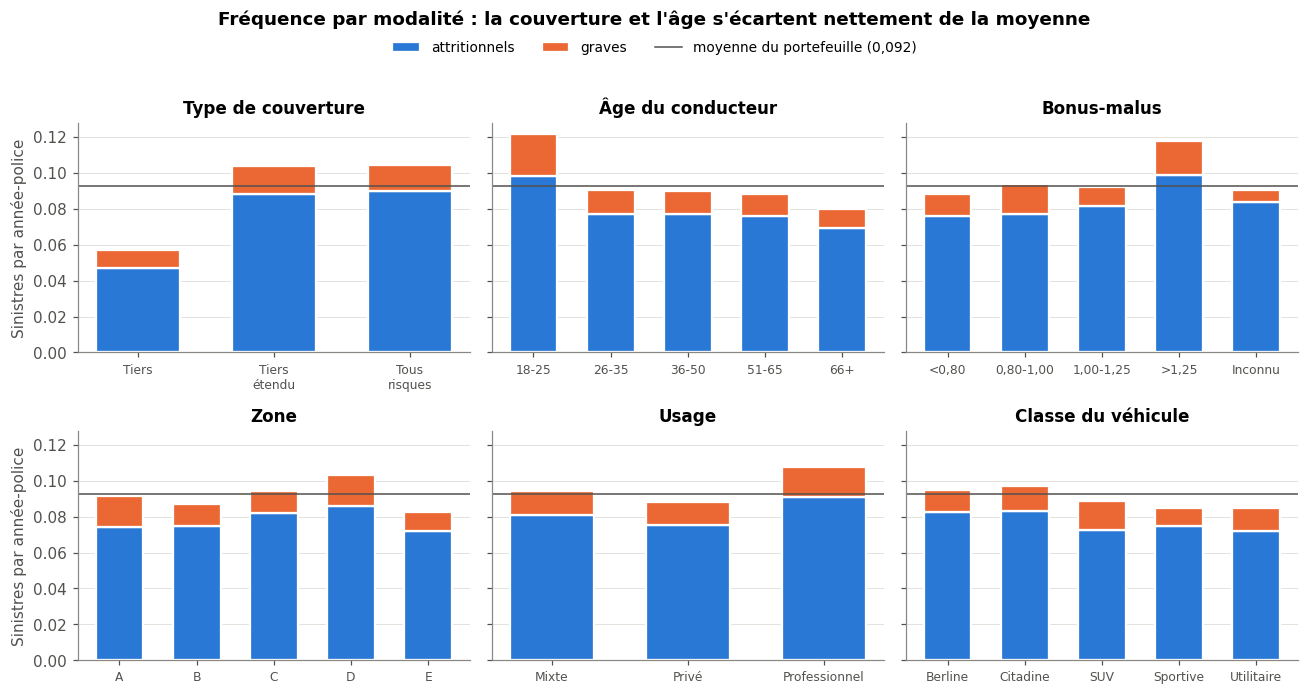

In [55]:
ordre = {'classe_bm': ['<0,80', '0,80-1,00', '1,00-1,25', '>1,25', 'Inconnu']}
vars_graph = [('type_couverture', 'Type de couverture'), ('classe_age', 'Âge du conducteur'),
              ('classe_bm', 'Bonus-malus'), ('zone_geo', 'Zone'), ('usage_vehicule', 'Usage'),
              ('classe_vehicule', 'Classe du véhicule')]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharey=True)
for ax, (v, titre) in zip(axes.flat, vars_graph):
    g = univarie(v)
    g = g.reindex([m for m in ordre.get(v, g.index) if m in g.index])
    g = g[g['exposition'] >= 50]      # modalités trop peu exposées (âge « Inconnu ») non tracées
    x = np.arange(len(g))
    ax.bar(x, g['freq_attr'], color=BLEU, width=0.62, edgecolor='white', linewidth=1.5, label='attritionnels')
    ax.bar(x, g['freq_grave'], bottom=g['freq_attr'], color=ORANGE, width=0.62, edgecolor='white',
           linewidth=1.5, label='graves')
    ax.axhline(freq_globale, color=ENCRE, lw=1)
    ax.set_xticks(x, [str(m).replace(' ', '\n', 1) if len(str(m)) > 9 else m for m in g.index], fontsize=8)
    ax.set_title(titre); ax.grid(axis='x', visible=False)
axes[0, 0].set_ylabel('Sinistres par année-police'); axes[1, 0].set_ylabel('Sinistres par année-police')
poignees, _ = axes[0, 0].get_legend_handles_labels()
poignees.append(plt.Line2D([], [], color=ENCRE, lw=1))
fig.legend(poignees, ['attritionnels', 'graves', f'moyenne du portefeuille ({freq_globale:.3f})'.replace('.', ',')],
           frameon=False, fontsize=9, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 0.955))
fig.suptitle("Fréquence par modalité : la couverture et l'âge s'écartent nettement de la moyenne",
             fontweight='bold', fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

**Lecture.** La prime pure est portée presque entièrement par les graves. Parmi les variables, le
**type de couverture** est de loin la plus discriminante : la fréquence d'un contrat Tiers est environ
deux fois plus faible, puisque ses sinistres non couverts sont exclus du périmètre. Les **jeunes
conducteurs** (18-25 ans) et les **bonus-malus supérieurs à 1,25** sont nettement plus sinistrés.
Les autres variables (classe, carburant, puissance, sexe) bougent peu. Les GLM de la partie D testent
formellement ces effets.

---
# Partie D — Modélisation GLM

| Sous-modèle | Cible | Offset / poids | Loi | Lien |
|---|---|---|---|---|
| Fréquence attritionnelle | `nb_attr` | offset `log_exposition` | Poisson (surdispersion testée) | log |
| Fréquence des graves | `nb_grave` | offset `log_exposition` | Poisson | log |
| Coût attritionnel | `charge_attr / nb_attr_cout` | poids `nb_attr_cout` | Gamma | log |
| Coût des graves | `charge_grave / nb_grave_cout` | poids `nb_grave_cout` | Gamma, ou moyenne mutualisée | log |

**Variables candidates**, toutes en classes (un tarif se lit par modalité) : `type_couverture`,
`classe_age`, `classe_bm`, `zone_geo`, `usage_vehicule`, `classe_vehicule`, `carburant`,
`classe_puissance`, `classe_vehic_age`. Le **sexe est exclu** : c'est un critère tarifaire interdit
dans l'Union européenne depuis 2012 (arrêt *Test-Achats*). L'ancienneté de permis n'est pas proposée
en plus de l'âge (corrélation 0,99).

**Sélection des variables** : élimination descendante par **test du rapport de vraisemblance**. On
part du modèle complet, on retire la variable la moins utile tant que sa p-valeur dépasse 5 %. Un
modèle plus petit généralise mieux : une variable sans effet réel n'ajoute que du bruit aux
prédictions.

**Regroupement des modalités.** Un test sur une variable à 5 modalités dilue l'effet d'une seule
modalité différente des autres. On regroupe donc les modalités dont le risque est le même dans
l'analyse univariée (partie C) :
- `type_couverture` : Tiers étendu et Tous risques (fréquences 0,088 et 0,090) → *Tiers étendu / Tous risques* ;
- `classe_age` : 26-35, 36-50 et 51-65 (fréquences 0,076 à 0,077) → *26-65* ; on garde les jeunes
  conducteurs 18-25 et les 66 ans et plus ;
- `classe_bm` : <0,80 et 0,80-1,00 (fréquences 0,076 et 0,077) → *<1,00*.

Une modalité de moins de 50 années-police (âge `Inconnu`, 4 contrats) est rattachée à la modalité
la plus exposée de sa variable, sinon son coefficient serait instable.

## D.1 Outils communs

In [56]:
candidates = ['type_couverture', 'classe_age', 'classe_bm', 'zone_geo', 'usage_vehicule',
              'classe_vehicule', 'carburant', 'classe_puissance', 'classe_vehic_age']
poisson   = sm.families.Poisson()
gamma_log = sm.families.Gamma(link=sm.families.links.Log())

# Regroupement des modalités au risque identique (analyse univariée, partie C)
regroupements = {
    'type_couverture': {'Tiers étendu': 'Tiers étendu / Tous risques', 'Tous risques': 'Tiers étendu / Tous risques'},
    'classe_age'     : {'26-35': '26-65', '36-50': '26-65', '51-65': '26-65'},
    'classe_bm'      : {'<0,80': '<1,00', '0,80-1,00': '<1,00'},
}
for v, reg in regroupements.items():
    base[v] = base[v].replace(reg)
    print(f'{v} : {sorted(base[v].unique())}')

# Regroupement des modalités de moins de 50 années-police avec la modalité la plus exposée
for v in candidates:
    expo_mod = base.groupby(v)['duree_exposition'].sum()
    petites = expo_mod[expo_mod < 50].index.tolist()
    if petites:
        base[v] = base[v].replace({m: expo_mod.idxmax() for m in petites})
        print(f'{v} : modalités {petites} regroupées avec « {expo_mod.idxmax()} »')

def formule(cible, variables):
    return f'{cible} ~ ' + (' + '.join(f'C({v})' for v in variables) if variables else '1')

def ajuste(cible, variables, data, famille, offset=None, poids=None):
    return smf.glm(formule(cible, variables), data=data, family=famille,
                   offset=offset, var_weights=poids).fit()

def selection(cible, data, famille, offset=None, poids=None, seuil=0.05):
    """Élimination descendante par test du rapport de vraisemblance (déviance)."""
    variables = list(candidates)
    while variables:
        complet = ajuste(cible, variables, data, famille, offset, poids)
        tests = []
        for v in variables:
            reduit = ajuste(cible, [w for w in variables if w != v], data, famille, offset, poids)
            ddl = complet.df_model - reduit.df_model
            stat = (reduit.deviance - complet.deviance) / complet.scale
            tests.append((v, stats.chi2.sf(stat, ddl)))
        v, pval = max(tests, key=lambda t: t[1])
        if pval < seuil:
            break
        print(f'   retire {v:<17} (p = {pval:.3f})')
        variables.remove(v)
    print('   → variables retenues :', variables or 'aucune (modèle constant)')
    return variables

def relativites(mod):
    ic = mod.conf_int()
    return pd.DataFrame({'relativité': np.exp(mod.params), 'IC 95 % bas': np.exp(ic[0]),
                         'IC 95 % haut': np.exp(ic[1]), 'p-valeur': mod.pvalues}).round(3)

sev_attr = base[base['nb_attr_cout'] > 0].assign(cout_moyen=lambda d: d['charge_attr'] / d['nb_attr_cout'])
sev_grav = base[base['nb_grave_cout'] > 0].assign(cout_moyen=lambda d: d['charge_grave'] / d['nb_grave_cout'])
sev_tous = base[base['nb_sinistres_cout'] > 0].assign(cout_moyen=lambda d: d['charge_totale'] / d['nb_sinistres_cout'])

type_couverture : ['Tiers', 'Tiers étendu / Tous risques']
classe_age : ['18-25', '26-65', '66+', 'Inconnu']
classe_bm : ['1,00-1,25', '<1,00', '>1,25', 'Inconnu']
classe_age : modalités ['Inconnu'] regroupées avec « 26-65 »


## D.2 GLM fréquence attritionnelle (Poisson)

In [57]:
print('Sélection — fréquence attritionnelle')
var_freq_attr = selection('nb_attr', base, poisson, offset=base['log_exposition'])
mod_freq_attr = ajuste('nb_attr', var_freq_attr, base, poisson, offset=base['log_exposition'])
disp = mod_freq_attr.pearson_chi2 / mod_freq_attr.df_resid
print(f"\nAIC : {mod_freq_attr.aic:.1f} | ratio de surdispersion (Pearson / ddl) : {disp:.3f} "
      f"{'→ Poisson plausible' if disp < 1.5 else '→ surdispersion : Binomiale Négative'}")
relativites(mod_freq_attr)

Sélection — fréquence attritionnelle


   retire classe_vehic_age  (p = 0.922)


   retire classe_puissance  (p = 0.528)


   retire zone_geo          (p = 0.419)


   retire classe_vehicule   (p = 0.424)


   retire classe_bm         (p = 0.267)


   retire carburant         (p = 0.264)


   retire usage_vehicule    (p = 0.109)


   → variables retenues : ['type_couverture', 'classe_age']

AIC : 7746.0 | ratio de surdispersion (Pearson / ddl) : 0.983 → Poisson plausible


,relativité,IC 95 % bas,IC 95 % haut,p-valeur
Intercept,0.059,0.046,0.074,0.000
C(type_couverture)[T.Tiers étendu / Tous risques],1.892,1.585,2.258,0.000
C(classe_age)[T.26-65],0.785,0.649,0.949,0.012
C(classe_age)[T.66+],0.703,0.477,1.038,0.076


## D.3 GLM fréquence des graves (Poisson)

In [58]:
print('Sélection — fréquence des graves')
var_freq_grave = selection('nb_grave', base, poisson, offset=base['log_exposition'])
mod_freq_grave = ajuste('nb_grave', var_freq_grave, base, poisson, offset=base['log_exposition'])
print(f"\nAIC : {mod_freq_grave.aic:.1f} | {int(base['nb_grave'].sum())} graves")
relativites(mod_freq_grave)

Sélection — fréquence des graves


   retire classe_puissance  (p = 0.943)


   retire carburant         (p = 0.809)


   retire classe_vehicule   (p = 0.741)


   retire usage_vehicule    (p = 0.551)


   retire classe_bm         (p = 0.252)


   retire zone_geo          (p = 0.148)


   retire classe_vehic_age  (p = 0.099)


   → variables retenues : ['type_couverture', 'classe_age']

AIC : 1935.0 | 169 graves


,relativité,IC 95 % bas,IC 95 % haut,p-valeur
Intercept,0.017,0.011,0.028,0.000
C(type_couverture)[T.Tiers étendu / Tous risques],1.459,0.988,2.154,0.057
C(classe_age)[T.26-65],0.543,0.364,0.811,0.003
C(classe_age)[T.66+],0.463,0.179,1.195,0.111


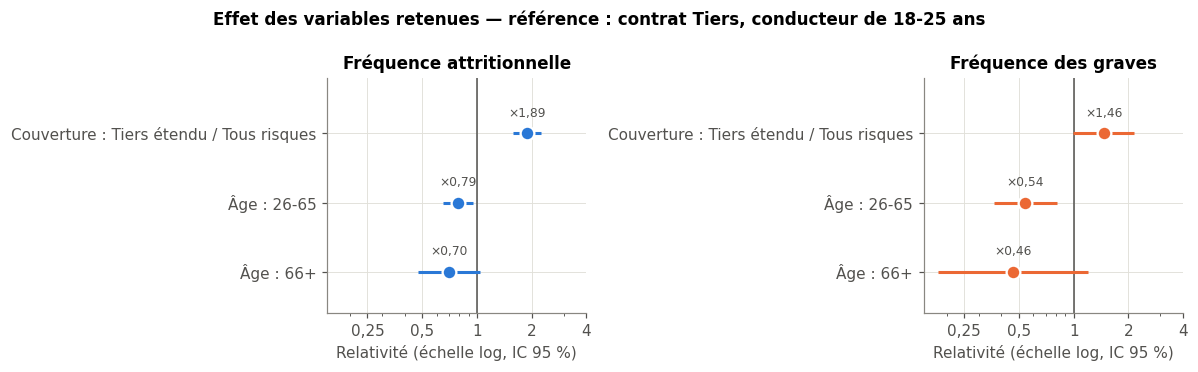

In [59]:
import re
NOMS_VAR = {'type_couverture': 'Couverture', 'classe_age': 'Âge', 'classe_bm': 'Bonus-malus', 'zone_geo': 'Zone',
            'usage_vehicule': 'Usage', 'classe_vehicule': 'Véhicule', 'carburant': 'Carburant'}
def etiquette(nom):
    m = re.match(r'C\((\w+)\)\[T\.(.+)\]', nom)
    return f'{NOMS_VAR.get(m.group(1), m.group(1))} : {m.group(2)}' if m else nom

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, mod, col, titre in [(axes[0], mod_freq_attr, BLEU, 'Fréquence attritionnelle'),
                            (axes[1], mod_freq_grave, ORANGE, 'Fréquence des graves')]:
    r = relativites(mod).drop('Intercept')
    y = np.arange(len(r))[::-1]
    ax.axvline(1, color=ENCRE, lw=1)
    ax.hlines(y, r['IC 95 % bas'], r['IC 95 % haut'], color=col, lw=2)
    ax.plot(r['relativité'], y, 'o', color=col, ms=9, mec='white', mew=1.5)
    for yi, v in zip(y, r['relativité']):
        ax.text(v, yi + 0.2, f'×{v:.2f}'.replace('.', ','), ha='center', va='bottom', fontsize=8, color=ENCRE)
    ax.set_yticks(y, [etiquette(i) for i in r.index]); ax.set_ylim(-0.6, len(r) - 0.2)
    ax.set_xscale('log'); ax.set_xlim(0.15, 4)
    ax.set_xticks([0.25, 0.5, 1, 2, 4], ['0,25', '0,5', '1', '2', '4'])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(titre); ax.set_xlabel('Relativité (échelle log, IC 95 %)')
fig.suptitle('Effet des variables retenues — référence : contrat Tiers, conducteur de 18-25 ans',
             fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

## D.4 GLM coût attritionnel (Gamma)

In [60]:
print('Sélection — coût attritionnel')
var_sev_attr = selection('cout_moyen', sev_attr, gamma_log, poids=sev_attr['nb_attr_cout'])
mod_sev_attr = ajuste('cout_moyen', var_sev_attr, sev_attr, gamma_log, poids=sev_attr['nb_attr_cout'])
cv = np.sqrt(mod_sev_attr.scale)
print(f"\n{len(sev_attr)} polices ({int(sev_attr['nb_attr_cout'].sum())} sinistres) | "
      f"coût moyen prédit {np.average(mod_sev_attr.predict(sev_attr), weights=sev_attr['nb_attr_cout']):,.0f} € | "
      f"CV estimé {cv:.2f}")
relativites(mod_sev_attr)

Sélection — coût attritionnel


   retire classe_vehic_age  (p = 0.873)


   retire classe_vehicule   (p = 0.679)


   retire classe_puissance  (p = 0.477)
   retire usage_vehicule    (p = 0.426)


   retire type_couverture   (p = 0.356)
   retire classe_age        (p = 0.330)
   retire carburant         (p = 0.201)
   → variables retenues : ['classe_bm', 'zone_geo']

953 polices (974 sinistres) | coût moyen prédit 957 € | CV estimé 0.75


,relativité,IC 95 % bas,IC 95 % haut,p-valeur
Intercept,875.023,755.363,1013.638,0.000
"C(classe_bm)[T.<1,00]",0.971,0.865,1.090,0.616
"C(classe_bm)[T.>1,25]",1.277,1.033,1.579,0.024
C(classe_bm)[T.Inconnu],0.772,0.507,1.176,0.229
C(zone_geo)[T.B],1.050,0.888,1.241,0.568
C(zone_geo)[T.C],1.072,0.922,1.245,0.367
C(zone_geo)[T.D],1.135,0.967,1.333,0.121
C(zone_geo)[T.E],1.289,1.076,1.544,0.006


## D.5 Coût des graves : GLM Gamma, GPD et moyenne mutualisée

In [61]:
print('Sélection — coût des graves')
var_sev_grave = selection('cout_moyen', sev_grav, gamma_log, poids=sev_grav['nb_grave_cout'])
cout_grave_moyen = base['charge_grave'].sum() / base['nb_grave_cout'].sum()
cout_grave_gpd = u_star + fit.sigma / (1 - fit.xi)       # espérance de la GPD ajustée en B.5.5
print(f"\nCoût moyen empirique des graves du périmètre : {cout_grave_moyen:,.0f} € "
      f"({int(base['nb_grave_cout'].sum())} graves)")
print(f"Espérance de la GPD au-delà de u* : u* + σ̂ / (1 − ξ̂) = {cout_grave_gpd:,.0f} €")
mod_sev_grave = ajuste('cout_moyen', var_sev_grave, sev_grav, gamma_log, poids=sev_grav['nb_grave_cout'])
relativites(mod_sev_grave)

Sélection — coût des graves


   retire usage_vehicule    (p = 0.873)


   retire classe_vehicule   (p = 0.345)


   retire type_couverture   (p = 0.293)
   retire classe_age        (p = 0.252)


   retire classe_vehic_age  (p = 0.312)
   retire classe_bm         (p = 0.152)
   retire classe_puissance  (p = 0.266)
   → variables retenues : ['zone_geo', 'carburant']

Coût moyen empirique des graves du périmètre : 50,252 € (169 graves)
Espérance de la GPD au-delà de u* : u* + σ̂ / (1 − ξ̂) = 47,358 €


,relativité,IC 95 % bas,IC 95 % haut,p-valeur
Intercept,28571.193,21547.724,37883.958,0.000
C(zone_geo)[T.B],1.722,1.214,2.444,0.002
C(zone_geo)[T.C],1.329,0.971,1.818,0.076
C(zone_geo)[T.D],1.708,1.243,2.346,0.001
C(zone_geo)[T.E],1.286,0.864,1.912,0.215
C(carburant)[T.Essence],1.418,1.113,1.806,0.005
C(carburant)[T.Hybride],0.938,0.652,1.349,0.728
C(carburant)[T.Électrique],1.565,0.975,2.513,0.064


**Lecture.** Le test de sélection conserve quelques variables pour le coût des graves, mais il repose
sur l'hypothèse Gamma d'un CV constant, que la queue des graves ne respecte pas (ξ̂ > 0, partie B) :
ses p-valeurs sont trop optimistes, et chaque relativité est estimée sur quelques dizaines de graves,
avec des intervalles de confiance larges. **On mutualise donc le coût des graves.** La moyenne
empirique et l'espérance de la GPD sont proches, ce qui confirme le modèle de queue de la partie B ;
on retient la moyenne empirique du périmètre, qui intègre les montants revalorisés.

## D.6 Modèles globaux (tous sinistres confondus) pour l'approche 1

In [62]:
print('Sélection — fréquence tous sinistres')
var_freq_tous = selection('nb_sinistres', base, poisson, offset=base['log_exposition'])
print('Sélection — coût tous sinistres')
var_sev_tous = selection('cout_moyen', sev_tous, gamma_log, poids=sev_tous['nb_sinistres_cout'])
spec_retenue = {'freq_attr': var_freq_attr, 'freq_grave': var_freq_grave, 'sev_attr': var_sev_attr,
                'freq_tous': var_freq_tous, 'sev_tous': var_sev_tous}

Sélection — fréquence tous sinistres


   retire classe_vehic_age  (p = 0.688)


   retire classe_vehicule   (p = 0.536)


   retire classe_puissance  (p = 0.465)


   retire carburant         (p = 0.373)


   retire zone_geo          (p = 0.262)


... (4 outputs left out)

   retire usage_vehicule    (p = 0.761)


   retire type_couverture   (p = 0.750)


   retire classe_vehicule   (p = 0.577)
   retire classe_vehic_age  (p = 0.354)


   retire zone_geo          (p = 0.224)
   retire classe_bm         (p = 0.069)
   retire classe_age        (p = 0.104)
   → variables retenues : ['carburant']


---
# Partie E — Comparaison des approches de pricing

1. **Global** : un GLM fréquence et un GLM coût sur tous les sinistres, sans distinction.
2. **Attritionnels seuls** : fréquence et coût des attritionnels ; les graves sont ignorés.
3. **Attritionnels + graves mutualisés** : approche 2 + une surprime identique pour tous
   (fréquence globale des graves × coût moyen des graves, par année-police).
4. **Attritionnels + graves spécifiques** : approche 2 + fréquence des graves par GLM × coût moyen
   des graves.

Chaque approche est jugée sur sa prime totale (doit reconstituer la charge) et sur sa capacité à
suivre la charge observée **segment par segment** (rapport prime / charge proche de 1).

In [63]:
def tarife(tr, te, spec):
    """Ajuste les modèles sur tr et renvoie les prédictions des 4 approches sur te."""
    o_tr, o_te = tr['log_exposition'], te['log_exposition']
    sa = tr[tr['nb_attr_cout'] > 0].assign(cm=lambda d: d['charge_attr'] / d['nb_attr_cout'])
    st = tr[tr['nb_sinistres_cout'] > 0].assign(cm=lambda d: d['charge_totale'] / d['nb_sinistres_cout'])
    m_fa = ajuste('nb_attr', spec['freq_attr'], tr, poisson, o_tr)
    m_fg = ajuste('nb_grave', spec['freq_grave'], tr, poisson, o_tr)
    m_ft = ajuste('nb_sinistres', spec['freq_tous'], tr, poisson, o_tr)
    m_sa = ajuste('cm', spec['sev_attr'], sa, gamma_log, poids=sa['nb_attr_cout'])
    m_st = ajuste('cm', spec['sev_tous'], st, gamma_log, poids=st['nb_sinistres_cout'])
    cout_g = tr['charge_grave'].sum() / tr['nb_grave_cout'].sum()
    freq_g = tr['nb_grave'].sum() / tr['duree_exposition'].sum()
    out = pd.DataFrame(index=te.index)
    out['nb_attr']  = m_fa.predict(te, offset=o_te)
    out['nb_grave'] = m_fg.predict(te, offset=o_te)
    out['nb_tous']  = m_ft.predict(te, offset=o_te)
    out['prime_1_global']        = out['nb_tous'] * m_st.predict(te)
    out['prime_2_attritionnels'] = out['nb_attr'] * m_sa.predict(te)
    out['prime_3_mutualisee']    = out['prime_2_attritionnels'] + freq_g * cout_g * te['duree_exposition']
    out['prime_4_specifique']    = out['prime_2_attritionnels'] + out['nb_grave'] * cout_g
    return out

primes = ['prime_1_global', 'prime_2_attritionnels', 'prime_3_mutualisee', 'prime_4_specifique']
noms_approches = ['1. Global', '2. Attritionnels seuls', '3. Graves mutualisés', '4. Graves spécifiques']
pred_complet = tarife(base, base, spec_retenue)
base = base.join(pred_complet[primes])

charge_obs = base['charge_totale'].sum()
comparaison_primes = pd.DataFrame({
    'Prime moyenne par police (€)': [base[c].mean() for c in primes],
    'Prime par année-police (€)'  : [base[c].sum() / expo_tot for c in primes],
    'CV'                          : [base[c].std() / base[c].mean() for c in primes],
    'Prime totale / charge'       : [base[c].sum() / charge_obs for c in primes],
}, index=noms_approches)
print(f'Charge observée du périmètre : {charge_obs:,.0f} €\n')
print(comparaison_primes.round(3).to_string())

print('\nRapport prime / charge observée par segment (1 = prime juste) :')
for v in ['type_couverture', 'classe_age', 'classe_bm']:
    t = base.groupby(v)[primes + ['charge_totale']].sum()
    t = t[primes].div(t['charge_totale'], axis=0)
    t.columns = noms_approches
    print(f'\n--- {v} ---'); print(t.round(2).to_string())

Charge observée du périmètre : 9,424,393 €

                        Prime moyenne par police (€)  Prime par année-police (€)     CV  Prime totale / charge
1. Global                                    443.307                     771.171  0.575                  1.011
2. Attritionnels seuls                        43.205                      75.159  0.517                  0.099
3. Graves mutualisés                         438.212                     762.309  0.429                  1.000
4. Graves spécifiques                        438.212                     762.309  0.521                  1.000

Rapport prime / charge observée par segment (1 = prime juste) :

--- type_couverture ---
                             1. Global  2. Attritionnels seuls  3. Graves mutualisés  4. Graves spécifiques
type_couverture                                                                                            
Tiers                             0.95                    0.09                  1.46           

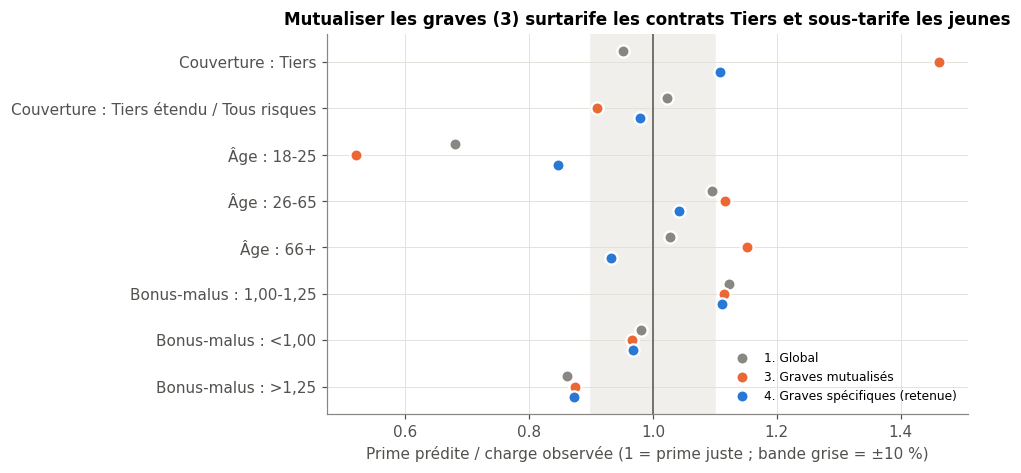

Bonus-malus « Inconnu » non représenté : un seul grave pour 155 années-police, rapport non interprétable.


In [64]:
segs = []
for v, lab in [('type_couverture', 'Couverture'), ('classe_age', 'Âge'), ('classe_bm', 'Bonus-malus')]:
    t = base.groupby(v)[primes + ['charge_totale']].sum()
    for mod in t.index.drop('Inconnu', errors='ignore'):
        segs.append([f'{lab} : {mod}'] + [t.loc[mod, c] / t.loc[mod, 'charge_totale']
                                         for c in ['prime_1_global', 'prime_3_mutualisee', 'prime_4_specifique']])
df_seg = pd.DataFrame(segs, columns=['segment', 'a1', 'a3', 'a4']).iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(df_seg))
ax.axvspan(0.9, 1.1, color='#f0efec', zorder=0)
ax.axvline(1, color=ENCRE, lw=1)
for col, c, lab, dy in [('a1', GRIS, '1. Global', 0.22), ('a3', ORANGE, '3. Graves mutualisés', 0),
                        ('a4', BLEU, '4. Graves spécifiques (retenue)', -0.22)]:
    ax.plot(df_seg[col], y + dy, 'o', color=c, ms=8, mec='white', mew=1.5, label=lab)
ax.set_yticks(y, df_seg['segment'])
ax.set_xlabel('Prime prédite / charge observée (1 = prime juste ; bande grise = ±10 %)')
ax.set_title('Mutualiser les graves (3) surtarife les contrats Tiers et sous-tarife les jeunes')
ax.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()
print('Bonus-malus « Inconnu » non représenté : un seul grave pour 155 années-police, rapport non interprétable.')

**Lecture.**
- Les approches 1, 3 et 4 reconstituent la charge totale (à 1 % près) ; l'approche 2 n'en couvre
  que 10 % : ignorer les graves n'est pas une option.
- **L'approche 3 (graves mutualisés) répartit mal la charge** : elle surtarife les contrats Tiers
  (prime / charge = 1,46) et sous-tarife les jeunes conducteurs (0,52), car les graves sont bien plus
  fréquents chez les jeunes et sur les couvertures avec dommages.
- **L'approche 4 (graves spécifiques) est la plus proche de la réalité par segment** (1,11 / 0,98 par
  couverture ; 0,85 / 1,04 / 0,93 par âge). L'approche 1 fait moins bien sur les jeunes (0,68) : un
  coût moyen unique mélange attritionnels et graves.
- Le rapport très élevé de la classe bonus-malus `Inconnu` vient d'une charge observée minuscule
  (un seul grave pour 155 années-police) : c'est de l'aléa, pas une erreur de prime.

Ces rapports sont calculés sur les données d'estimation : la partie F les vérifie sur des polices
jamais vues par les modèles.

---
# Partie F — Séparation Train / Test et validation

**Constat :** toutes les polices ont une `date_effet_contrat` en 2023 (cohorte de souscription
unique) : pas de split temporel classique au niveau police.

**Décision :** split **aléatoire stratifié** sur la présence d'un sinistre grave, 70 % train / 30 %
test. Les modèles sont réestimés sur le train seul, puis jugés sur le test :
- nombre de sinistres prédit / observé, et **gain de déviance** par rapport à un modèle sans variable ;
- **fréquence prédite / observée par quintile de risque** (le modèle classe-t-il bien les assurés ?) ;
- prime prédite / charge observée, globalement et par segment.

On compare la **spécification initiale** (variables choisies a priori : zone, usage, sexe, carburant,
classe, bonus-malus, puissance) à la **spécification retenue** par sélection (partie D).

Un contrôle temporel complète la validation : modèles de fréquence estimés sur les sinistres de 2023,
appliqués à l'exposition de 2024.

In [65]:
base['a_un_grave'] = (base['nb_grave'] > 0).astype(int)
train, test = train_test_split(base, test_size=0.3, random_state=42, stratify=base['a_un_grave'])
train, test = train.copy(), test.copy()
print(f"Train : {len(train)} polices ({train['nb_sinistres'].sum():.0f} sinistres, {train['nb_grave'].sum():.0f} graves)")
print(f"Test  : {len(test)} polices ({test['nb_sinistres'].sum():.0f} sinistres, {test['nb_grave'].sum():.0f} graves)")

initiales = ['zone_geo', 'usage_vehicule', 'sexe', 'carburant', 'classe_vehicule', 'classe_bm', 'classe_puissance']
spec_initiale = {'freq_attr': initiales, 'freq_grave': ['zone_geo', 'usage_vehicule'], 'sev_attr': initiales,
                 'freq_tous': initiales, 'sev_tous': initiales}
specs = {'initiale': spec_initiale, 'retenue': spec_retenue}
pred_test = {nom: tarife(train, test, sp) for nom, sp in specs.items()}

def deviance_poisson(y, mu):
    y, mu = np.asarray(y, float), np.asarray(mu, float)
    return 2 * np.sum(np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))

lignes = []
for cible, col in [('attritionnels', 'nb_attr'), ('graves', 'nb_grave'), ('tous', 'nb_sinistres')]:
    y = test[col]
    mu0 = train[col].sum() / train['duree_exposition'].sum() * test['duree_exposition']
    d0 = deviance_poisson(y, mu0)
    lignes.append({'sinistres': cible, 'spécification': 'constante (référence)', 'observés': int(y.sum()),
                   'prédits': round(mu0.sum(), 1), 'écart (%)': round((mu0.sum() / y.sum() - 1) * 100, 1),
                   'gain de déviance vs constante (%)': 0.0})
    for nom in specs:
        mu = pred_test[nom]['nb_tous' if cible == 'tous' else col]
        lignes.append({'sinistres': cible, 'spécification': nom, 'observés': int(y.sum()),
                       'prédits': round(mu.sum(), 1), 'écart (%)': round((mu.sum() / y.sum() - 1) * 100, 1),
                       'gain de déviance vs constante (%)': round((1 - deviance_poisson(y, mu) / d0) * 100, 2)})
print('\n=== Fréquence sur l\'échantillon test ===')
print(pd.DataFrame(lignes).to_string(index=False))

print('\n=== Prime prédite / charge observée sur le test ===')
charge_test = test['charge_totale'].sum()
print(f'Charge observée du test : {charge_test:,.0f} €')
print(pd.DataFrame({nom: [pred_test[nom][c].sum() / charge_test for c in primes] for nom in specs},
                   index=noms_approches).round(3).to_string())

Train : 15050 polices (786 sinistres, 118 graves)
Test  : 6450 polices (357 sinistres, 51 graves)



=== Fréquence sur l'échantillon test ===
    sinistres         spécification  observés  prédits  écart (%)  gain de déviance vs constante (%)
attritionnels constante (référence)       306    288.5       -5.7                               0.00
attritionnels              initiale       306    287.9       -5.9                              -0.00
attritionnels               retenue       306    288.4       -5.8                               1.09
       graves constante (référence)        51     51.0       -0.1                               0.00
       graves              initiale        51     50.8       -0.3                              -0.11
       graves               retenue        51     50.8       -0.3                               1.00
         tous constante (référence)       357    339.4       -4.9                               0.00
         tous              initiale       357    338.5       -5.2                              -0.09
         tous               retenue       357    

initiale : fréquence observée du quintile 5 / quintile 1 = 1.17
retenue  : fréquence observée du quintile 5 / quintile 1 = 2.42


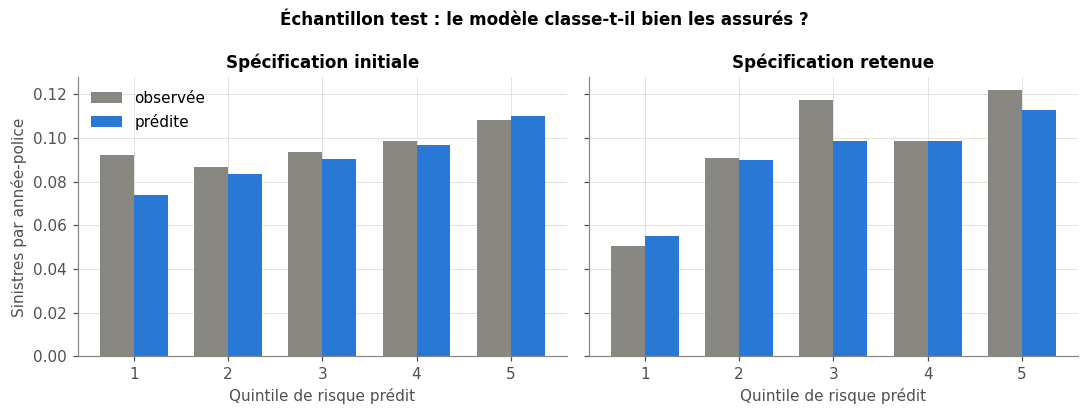


=== Test : sinistres prédits / observés par segment (approche 4, spécification retenue) ===

--- type_couverture ---
                             observés  prédits  prédits / observés
type_couverture                                                   
Tiers                              52    52.44                1.01
Tiers étendu / Tous risques       305   286.80                0.94

--- classe_age ---
            observés  prédits  prédits / observés
classe_age                                       
18-25             44    44.41                1.01
26-65            301   283.35                0.94
66+               12    11.48                0.96

--- classe_bm ---
           observés  prédits  prédits / observés
classe_bm                                       
1,00-1,25        69    70.40                1.02
<1,00           263   247.06                0.94
>1,25            21    16.89                0.80
Inconnu           4     4.89                1.22


In [66]:
# Fréquence observée vs prédite par quintile de risque prédit (échantillon test)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, nom in zip(axes, specs):
    pr = pred_test[nom]
    f_pred = (pr['nb_attr'] + pr['nb_grave']) / test['duree_exposition']
    q = pd.qcut(f_pred.rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
    t = pd.DataFrame({'q': q, 'obs': test['nb_sinistres'], 'pred': pr['nb_attr'] + pr['nb_grave'],
                      'e': test['duree_exposition']}).groupby('q', observed=True).sum()
    ax.bar(t.index.astype(int) - 0.18, t['obs'] / t['e'], width=0.36, color=GRIS, label='observée')
    ax.bar(t.index.astype(int) + 0.18, t['pred'] / t['e'], width=0.36, color=BLEU, label='prédite')
    ax.set_title(f'Spécification {nom}'); ax.set_xlabel('Quintile de risque prédit')
    print(f"{nom:<9}: fréquence observée du quintile 5 / quintile 1 = {(t['obs'] / t['e']).iloc[-1] / (t['obs'] / t['e']).iloc[0]:.2f}")
axes[0].set_ylabel('Sinistres par année-police'); axes[0].legend(frameon=False)
fig.suptitle('Échantillon test : le modèle classe-t-il bien les assurés ?', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

print('\n=== Test : sinistres prédits / observés par segment (approche 4, spécification retenue) ===')
pr = pred_test['retenue']
for v in ['type_couverture', 'classe_age', 'classe_bm']:
    t = pd.DataFrame({v: test[v], 'observés': test['nb_sinistres'], 'prédits': pr['nb_attr'] + pr['nb_grave']}).groupby(v).sum()
    t['prédits / observés'] = t['prédits'] / t['observés']
    print(f'\n--- {v} ---'); print(t.round(2).to_string())

In [67]:
# Contrôle temporel : fréquences estimées sur 2023, appliquées à l'exposition 2024
b23 = base[base['expo_2023'] > 0].assign(off=lambda d: np.log(d['expo_2023']))
b24 = base[base['expo_2024'] > 0].assign(off=lambda d: np.log(d['expo_2024']))
temporel = {}
for cible, variables in [('attr', var_freq_attr), ('grave', var_freq_grave)]:
    m23 = ajuste(f'nb_{cible}_2023', variables, b23, poisson, b23['off'])
    pred24, obs24 = m23.predict(b24, offset=b24['off']).sum(), base[f'nb_{cible}_2024'].sum()
    temporel[cible] = (obs24, pred24)
    print(f'{cible:<6}: 2024 observé {obs24:>4.0f} | prédit par le modèle 2023 {pred24:>6.1f} '
          f'| écart {(pred24 / obs24 - 1) * 100:+.1f} %')

base.to_csv('base_tarification.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
print('\nFichier écrit : base_tarification.csv (base_B + primes des 4 approches)')

attr  : 2024 observé  332 | prédit par le modèle 2023  325.1 | écart -2.1 %


grave : 2024 observé   58 | prédit par le modèle 2023   56.4 | écart -2.8 %



Fichier écrit : base_tarification.csv (base_B + primes des 4 approches)


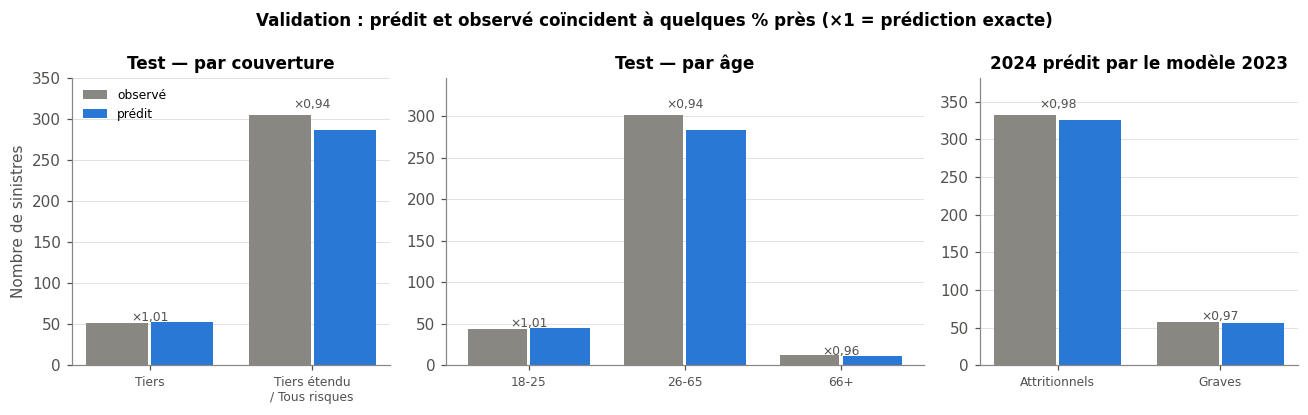

In [68]:
pr = pred_test['retenue']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 3, 2]})

def barres(ax, labels, obs, pred, titre):
    x = np.arange(len(labels))
    ax.bar(x - 0.2, obs, 0.38, color=GRIS, label='observé')
    ax.bar(x + 0.2, pred, 0.38, color=BLEU, label='prédit')
    for xi, o, p_ in zip(x, obs, pred):
        ax.text(xi, max(o, p_) * 1.03, f'×{p_ / o:.2f}'.replace('.', ','), ha='center', fontsize=8, color=ENCRE)
    ax.set_xticks(x, labels, fontsize=8); ax.set_title(titre); ax.grid(axis='x', visible=False)
    ax.set_ylim(0, max(max(obs), max(pred)) * 1.15)

for ax, v, titre in [(axes[0], 'type_couverture', 'Test — par couverture'), (axes[1], 'classe_age', 'Test — par âge')]:
    t = pd.DataFrame({v: test[v], 'obs': test['nb_sinistres'],
                      'pred': pr['nb_attr'] + pr['nb_grave']}).groupby(v).sum()
    barres(ax, [str(m).replace(' / ', '\n/ ') for m in t.index], t['obs'].values, t['pred'].values, titre)
barres(axes[2], ['Attritionnels', 'Graves'], [temporel['attr'][0], temporel['grave'][0]],
       [temporel['attr'][1], temporel['grave'][1]], '2024 prédit par le modèle 2023')
axes[0].set_ylabel('Nombre de sinistres'); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Validation : prédit et observé coïncident à quelques % près (×1 = prédiction exacte)',
             fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

**Lecture de la validation.**
- **Niveau global.** Sur le test, la prime des approches 3 et 4 couvre la charge observée à 2,5 % près.
  Le nombre de sinistres attritionnels est sous-estimé d'environ 6 %, mais le modèle constant fait la
  même erreur : l'écart vient du tirage de l'échantillon test (un peu plus sinistré que le train),
  pas des modèles. Le contrôle temporel le confirme : estimés sur 2023, les modèles prédisent 2024 à
  2 – 3 % près, pour les attritionnels comme pour les graves.
- **Segmentation.** La spécification retenue classe beaucoup mieux les assurés : le quintile le plus
  risqué a une fréquence observée 2,4 fois plus élevée que le moins risqué, contre 1,2 avec les
  variables initiales. Par segment, prédit et observé coïncident à ±6 % pour la couverture et l'âge
  (jeunes conducteurs : 1,01).
- **Limites.** Les segments de petite taille (bonus-malus > 1,25, bonus-malus inconnu) restent
  instables : quelques sinistres suffisent à déplacer le rapport.

---
# Synthèse — points clés pour le rapport

**1. Démarche.** Fiabilisation des données (corriger plutôt que supprimer, `Inconnu` plutôt
qu'inventer) → montants traités selon le statut et la nature → seuil de gravité par POT, confronté à
trois autres méthodes → fréquence × coût → GLM avec sélection des variables par test du rapport de
vraisemblance → quatre approches de prime → validation sur un échantillon test et sur l'année 2024.

**2. Données.**
- Contrats : 21 603 → **21 500** (seuls les 103 doublons exacts, vérifiés colonne par colonne, sont
  retirés), 12 359 années-police. 51 expositions codées corrigées (plafond à 1 an ou médiane),
  68 bonus-malus codés convertis (−0,5 → 0,50 ; 0 → 1,00 ; 12 → 1,20).
- Âge : 404 âges reconstruits à partir de l'ancienneté de permis (erreur moyenne 1,5 an, contre
  10,4 ans pour l'âge médian) ; 4 âges et 258 bonus-malus impossibles à reconstruire → classe `Inconnu`.
- Sinistres : 1 320 → 1 304 (10 doublons exacts, 6 orphelins) ; **1 143 dans le périmètre de
  tarification** (155 hors garantie Tiers, 5 sans suite, 1 hors période exclus).
- Montants : à nature égale, dossiers ouverts et clos ont le même niveau de montant (tests de
  Mann-Whitney non significatifs) ; les 32 montants inconnus, codés ou forfaitaires du périmètre sont
  revalorisés par le coût moyen de leur nature.

**3. Séparation attritionnels / graves.** Seuil **u* = 9 000 €** (POT, σ̂ minimal sur le domaine de
validité de la GPD) ; même partition que le plus grand écart et le mélange log-normal, et 100 % de
concordance avec la nature du sinistre ; les quantiles coupent la population des graves. Sur le
périmètre : **169 graves (14,8 % des sinistres) portent 90,1 % de la charge** ; coût moyen 50 250 €
contre 957 € pour les attritionnels.

**4. Modèles.** Fréquence 0,0925 sinistre par année-police, prime pure 763 € par année-police
(75 € attritionnels + 687 € graves).
- Fréquence attritionnelle (Poisson, pas de surdispersion) : couverture avec dommages ×1,89 ; 26-65
  ans ×0,79 et 66 ans et plus ×0,70 par rapport aux 18-25 ans.
- Fréquence des graves : couverture ×1,46 ; jeunes conducteurs environ 1,8 fois plus exposés.
- Coût attritionnel (Gamma) : bonus-malus > 1,25 ×1,28, zone E ×1,29.
- Coût des graves mutualisé (50 250 €, proche de l'espérance de la GPD, 47 360 €).
- Sexe exclu (interdit en tarification dans l'UE) ; zone, usage, véhicule, carburant et puissance
  n'ont pas d'effet significatif sur la fréquence.

**5. Approche retenue : n° 4** (attritionnels + graves spécifiques). Elle reconstitue la charge et
suit le mieux la charge observée par couverture et par âge ; l'approche 2 n'en couvre que 10 %,
l'approche 3 surtarife les contrats Tiers (×1,46) et sous-tarife les jeunes (×0,52).

**6. Validation.** Sur le test : prime / charge = 1,02 ; prédit / observé à ±6 % par couverture et
par âge ; pouvoir de classement 2,4 (quintile le plus risqué / le moins risqué) contre 1,2 pour les
variables initiales. Modèles 2023 appliqués à 2024 : écart de −2 % (attritionnels) et −3 % (graves).

**7. Limites.**
- 48 % des graves sont des dossiers ouverts : les montants provisoires ne semblent pas sous-évalués
  à nature égale, mais l'absence de triangle de développement empêche de le garantir.
- 12 montants identiques à 12 000 € d'origine inexpliquée (revalorisés).
- 169 graves seulement : coût des graves mutualisé, fréquence des graves estimée avec des intervalles
  de confiance larges.